In [1]:
from modules.dataset.make_dataset import make_dataset, dataset_split, dataset_split_by_recording, NpzDataPipeline, TaskDataset, TASK_TARGETS, binary_labels, binary_labels_grouped, indices_by_label
from modules.nn import BranchedCoughCNN, DefaultCNN, FocalLoss
import polars as pl
import numpy as np
import torch
from torchinfo import summary
from torch.utils.data import Subset
import torch.nn as nn
import torch.optim as optim
from typing import Sequence
from sklearn.metrics import f1_score, roc_auc_score, precision_recall_curve, auc, confusion_matrix, ConfusionMatrixDisplay
from modules.preprocessing.dataframe_process import filter_coughvid_df

In [2]:
dataset: NpzDataPipeline = NpzDataPipeline("data/final_processed_dataset.npz")
device: torch.types.Device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [3]:
import os

def load_checkpoint(filepath: str, model: nn.Module, optimizer: optim.Optimizer) -> tuple[nn.Module, optim.Optimizer, int, float]:
    print("=> Loading checkpoint")
    # Use weights_only=True for security best practices
    checkpoint: dict = torch.load(filepath, weights_only=True) 
    
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    epoch: int = checkpoint['epoch']
    loss: float = checkpoint['loss']
    return model, optimizer, epoch, loss

def save_checkpoint(model: nn.Module, optimizer: optim.Optimizer, epoch: int, loss: float, filename: str ="checkpoint.pth.tar") -> None:
    print("=> Saving checkpoint")
    checkpoint = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'loss': loss,
    }
    torch.save(checkpoint, filename)

# ---- Crash-proof run state: per-epoch autosave + resume (train_binary) ----
RUN_STATE_DIR: str = "run_state"
os.makedirs(RUN_STATE_DIR, exist_ok=True)

def _ckpt_path(name: str) -> str:
    return os.path.join(RUN_STATE_DIR, f"{name}_latest.pth.tar")

def _atomic_torch_save(obj: dict, path: str) -> None:
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)  # crash mid-write never corrupts the good file

def resume_or_fresh(
    name: str,
    model: nn.Module,
    optimizer: optim.Optimizer,
    scheduler: optim.lr_scheduler.LRScheduler,
    scaler: torch.amp.GradScaler,
    num_epochs: int,
) -> tuple[int, dict[str, list[float]]]:
    """Load `run_state/{name}_latest.pth.tar` into model/opt/sched/scaler if it exists.
    Returns (epochs_done, history). If the run is already complete, also registers
    the model in trained_models so post-training eval works on a fresh kernel."""
    path = _ckpt_path(name)
    fresh: dict[str, list[float]] = {"train_loss": [], "val_loss": [], "val_acc": [], "val_F1": [], "val_auc": [], "val_pr_auc": []}
    if not os.path.exists(path):
        return 0, fresh
    ckpt = torch.load(path, weights_only=True, map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    scheduler.load_state_dict(ckpt["scheduler_state_dict"])
    scaler.load_state_dict(ckpt["scaler_state_dict"])
    epochs_done: int = ckpt["epoch"] + 1  # 'epoch' is the 0-based index of the last COMPLETED epoch
    history: dict[str, list[float]] = ckpt["history"]
    if epochs_done >= num_epochs:
        trained_models[name] = model  # finished run: restore into eval registry, no retrain
    print(f"=> [{name}] resumed at epoch {epochs_done + 1}/{num_epochs}" if epochs_done < num_epochs
          else f"=> [{name}] already complete ({num_epochs}/{num_epochs} epochs) — restored, no retrain")
    return epochs_done, history

In [4]:
# ---- Experiment setup (shared) ----
from modules.dataset.make_dataset import AugmentedSubset
from modules.preprocessing.audio_process import WaveformAugmentor, SpecAugmentations, MelSpectrogramPipeline, SpectMFCCPipeline
from tqdm.auto import tqdm

num_epochs: int = 60
SEED: int = 42  # identical split across all experiments
BATCH_SIZE: int = 128

# n_mel=64 per Chang et al. (research_results.md fix #6): 64 mel bins @ 16 kHz
mel_train_plain: SpectMFCCPipeline = SpectMFCCPipeline(combind=True).to(device)  # no spec aug
mel_train_spec: SpectMFCCPipeline = SpectMFCCPipeline(transforms=SpecAugmentations(), combind=True).to(device)
mel_eval: SpectMFCCPipeline = SpectMFCCPipeline(combind=True).to(device)         # plain for validation

# speed: compile only the eval mel path; train paths stay eager (spec-aug masks/augmentor randomize per step)
mel_eval = torch.compile(mel_eval) if device.type == "cuda" else mel_eval  # CPU inductor needs MSVC cl.exe; skip
torch.backends.cudnn.benchmark = True
torch.set_float32_matmul_precision("high")



In [5]:
def tune_threshold(y_true: np.ndarray, probs: np.ndarray) -> float:
    """Youden's J on val: pick the threshold maximizing TPR - FPR (falls back to 0.5 if one class)."""
    from sklearn.metrics import roc_curve
    try:
        fpr, tpr, thr = roc_curve(y_true, probs)
        return float(thr[np.argmax(tpr - fpr)])
    except ValueError:
        return 0.5

In [6]:
# ---- Recording-wise split (shared across experiments) ----
# split by SOURCE RECORDING so sibling segments of one clip can't leak across splits

dataset.load_data()
dataset.load_paths()

train_subset, val_subset, test_subset = dataset_split_by_recording(dataset, dataset.paths, 0.7, 0.2, seed=SEED)

# sanity: class mix per split (reseed if test has almost no COVID samples)
LABELS_INV = {0: "healthy", 1: "COVID-19", 2: "symptomatic"}
for name, s in [("train", train_subset), ("val", val_subset), ("test", test_subset)]:
    counts = np.bincount([int(dataset.labels[i]) for i in s.indices], minlength=3)
    print(name, {LABELS_INV[k]: int(v) for k, v in enumerate(counts)})

healthy: 35672 (74.6%)
COVID-19: 2398 (5.0%)
symptomatic: 9772 (20.4%)
total: 47842
train {'healthy': 24846, 'COVID-19': 1707, 'symptomatic': 6943}
val {'healthy': 7190, 'COVID-19': 505, 'symptomatic': 1875}
test {'healthy': 3636, 'COVID-19': 186, 'symptomatic': 954}


In [7]:
# ---- Per-class loss weights (Chang et al. method: weight in the loss, NO sampler) ----
# weights come from the TRAIN split only, per one-vs-rest binary task
train_labels = torch.tensor([int(dataset.labels[i]) for i in train_subset.indices])

def class_weight_for(positive: int) -> torch.Tensor:
    """Inverse-frequency weights [rest, positive] for one-vs-rest task: rare class gets the BIGGER weight."""
    counts = torch.bincount(train_labels, minlength=3)
    n_pos = counts[positive].float()
    n_neg = (counts.sum() - counts[positive]).float()
    w = torch.tensor([1.0 / n_neg, 1.0 / n_pos])
    return w / w.sum() * 2.0  # normalize so mean weight is 1 (keeps loss scale comparable)

In [8]:
_model = DefaultCNN(num_classes=2)
# combined pipeline: 64 mel + 40 MFCC = 104 freq bins, 3 channels (spec, mfcc, delta)
summary(_model, input_size=(64, 3, 104, 32))

Layer (type:depth-idx)                   Output Shape              Param #
DefaultCNN                               [64, 2]                   --
├─Sequential: 1-1                        [64, 128, 13, 4]          --
│    └─DepthwiseSeparableBlock: 2-1      [64, 32, 52, 16]          --
│    │    └─Sequential: 3-1              [64, 32, 52, 16]          193
│    └─DepthwiseSeparableBlock: 2-2      [64, 64, 26, 8]           --
│    │    └─Sequential: 3-2              [64, 64, 26, 8]           2,528
│    └─DepthwiseSeparableBlock: 2-3      [64, 128, 13, 4]          --
│    │    └─Sequential: 3-3              [64, 128, 13, 4]          9,152
├─Sequential: 1-2                        [64, 2]                   --
│    └─AdaptiveAvgPool2d: 2-4            [64, 128, 1, 1]           --
│    └─Flatten: 2-5                      [64, 128]                 --
│    └─Linear: 2-6                       [64, 128]                 16,512
│    └─LeakyReLU: 2-7                    [64, 128]                 --
│   

In [9]:
# ---- Binary experiment runner (one-vs-rest AND cascade task views) ----
def train_binary(name: str, positive: int, use_wave: bool, use_spec: bool,
                 positives: frozenset[int] | None = None,
                 task: str | None = None) -> dict[str, list[float]]:
    """Binary task over the audio data.
    - One-vs-rest (default): positive class = `positive`.
    - Grouped (positives=...): 1 where raw label in `positives`.
    - task='covid_symp_vs_healthy' / 'covid_vs_symp': data comes from TaskDataset,
      which relabels (and for covid_vs_symp filters healthy out entirely).
    Raw 3-class labels still flow through loaders (augment prob dicts key on them);
    relabel happens at the loss/metrics step.
    Crash-proof: state autosaves to run_state/{name}_latest.pth.tar every epoch;
    re-running resumes mid-run (or short-circuits if already complete)."""
    history: dict[str, list[float]] = {"train_loss": [], "val_loss": [], "val_acc": [], "val_F1": [], "val_auc": [], "val_pr_auc": []}

    if task is not None:
        task_ds = TaskDataset(dataset, task)
        # split indices may fall outside the task population (covid_vs_symp drops
        # healthy) — keep only base indices the task dataset actually contains
        have = set(task_ds.indices)
        tr_base = [i for i in train_subset.indices if i in have]
        va_base = [i for i in val_subset.indices if i in have]
        tr_pos = task_ds.positions_for(tr_base)
        va_pos = task_ds.positions_for(va_base)
        tgt = TASK_TARGETS[task](dataset.labels[torch.tensor(tr_base)])
        n_pos = int(tgt.sum()); n_neg = len(tgt) - n_pos
    else:
        tr_idx, va_idx = train_subset.indices, val_subset.indices
        if positives is not None:
            in_group = torch.isin(train_labels, torch.tensor(sorted(positives)))
            counts = torch.tensor([(~in_group).sum(), in_group.sum()]).float()
        else:
            counts = torch.bincount(train_labels, minlength=3).float()
            counts = torch.tensor([counts.sum() - counts[positive], counts[positive]])
        w = 1.0 / counts.clamp(min=1)
        w = w / w.sum() * 2.0  # normalize so mean weight is 1 (keeps loss scale comparable)
        w = w.to(device)

    if task is not None:
        w = 1.0 / torch.tensor([n_neg, n_pos], dtype=torch.float32).clamp(min=1)
        w = w / w.sum() * 2.0  # normalize so mean weight is 1
        w = w.to(device)

    criterion: nn.Module = FocalLoss(alpha=w, gamma=2.0)  # weighted focal: down-weights easy samples, alpha keeps class balance

    if device.type == "cuda":
        model: nn.Module = torch.compile(DefaultCNN(num_classes=2)).to(device)
    else:
        model = DefaultCNN(num_classes=2).to(device)  # speed: compile only on CUDA

    optimizer: optim.AdamW = optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-2)
    scaler: torch.amp.GradScaler = torch.amp.GradScaler(enabled=(device.type == "cuda"))
    scheduler: optim.lr_scheduler.CosineAnnealingLR = optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=num_epochs, eta_min=1e-6
    )

    # crash recovery: pick up where the last run left off (0 + fresh history if none)
    epochs_done, history = resume_or_fresh(name, model, optimizer, scheduler, scaler, num_epochs)

    mel_train: SpectMFCCPipeline = mel_train_spec if use_spec else mel_train_plain

    if task is not None:
        tr_src, va_src = task_ds, task_ds  # indexed by task positions
    else:
        tr_src = va_src = dataset  # indexed by base indices

    # Train loader: AugmentedSubset (WaveformAugmentor) when use_wave, else plain Subset
    train_ds: AugmentedSubset | Subset = AugmentedSubset(
        tr_src, tr_pos if task is not None else tr_idx,
        WaveformAugmentor(16_000)
    ) if use_wave else Subset(tr_src, tr_pos if task is not None else tr_idx)

    train_loader: torch.utils.data.DataLoader = torch.utils.data.DataLoader(
        train_ds, BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True,
        persistent_workers=True, prefetch_factor=4,  # speed: no worker respawn / keep queues full
    )

    val_loader: torch.utils.data.DataLoader = torch.utils.data.DataLoader(
        Subset(va_src, va_pos if task is not None else va_idx), BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True,
        persistent_workers=True, prefetch_factor=4,
    )

    def relabel(raw: torch.Tensor) -> torch.Tensor:
        if task is not None:
            return TASK_TARGETS[task](raw)
        if positives is not None:
            return binary_labels_grouped(raw, positives)
        return binary_labels(raw, positive)

    for epoch in range(epochs_done, num_epochs):
        # Training Phase
        model.train()
        running_loss = 0.0

        for waveforms, labels in tqdm(train_loader, desc=f"[{name}] train {epoch+1}/{num_epochs}", leave=False):
            waveforms = waveforms.to(device, non_blocking=True)
            raw = labels.long().to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            # Features must run in fp32 OUTSIDE autocast: TimeStretch/complex spectrogram
            # ops produce NaN under fp16 autocast
            images = mel_train(waveforms, raw)  # (B, 3, F, T) — pipeline already returns 3 channels
            if images.ndim == 3:  # pipeline dropped the channel dim on a 1-sample batch
                images = images.unsqueeze(0)

            target = relabel(raw)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                outputs = model(images)
                loss = criterion(outputs, target)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item()

        scheduler.step()

        # Validation Phase
        model.eval()
        val_loss = 0.0
        correct = 0
        total = 0

        all_preds = []
        all_targets = []
        all_probs = []

        with torch.inference_mode():
            for waveforms, labels in tqdm(val_loader, desc=f"[{name}] val {epoch+1}/{num_epochs}", leave=False):
                waveforms = waveforms.to(device, non_blocking=True)
                raw = labels.long().to(device, non_blocking=True)

                images = mel_eval(waveforms)  # no labels -> no spec aug; fp32 outside autocast
                if images.ndim == 3:  # pipeline dropped the channel dim on a 1-sample batch
                    images = images.unsqueeze(0)

                target = relabel(raw)
                with torch.amp.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                    outputs = model(images)
                    loss = criterion(outputs, target)

                all_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
                all_targets.extend(target.cpu().numpy())
                all_probs.extend(torch.softmax(outputs, dim=1)[:, 1].cpu().numpy())

                val_loss += loss.item()
                total += raw.size(0)
                correct += (torch.argmax(outputs, dim=1) == target).sum().item()

        val_macro_f1 = f1_score(all_targets, all_preds, average="macro")
        val_auc_score = roc_auc_score(all_targets, all_probs)
        pr_curve, pr_targets, _ = precision_recall_curve(all_targets, all_probs)
        val_pr = auc(pr_targets, pr_curve)
        train_epoch_loss = running_loss / len(train_loader)
        val_epoch_loss = val_loss / len(val_loader)
        val_accuracy = 100.0 * correct / total

        history["train_loss"].append(train_epoch_loss)
        history["val_loss"].append(val_epoch_loss)
        history["val_F1"].append(val_macro_f1)
        history["val_acc"].append(val_accuracy)
        history["val_auc"].append(val_auc_score)
        history["val_pr_auc"].append(val_pr)

        # autosave FULL state every epoch so a crash never loses progress
        _atomic_torch_save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "history": history,
        }, _ckpt_path(name))
        if (epoch + 1) % 10 == 0 or epoch + 1 == num_epochs:
            print(f"=> [{name}] checkpoint saved (epoch {epoch+1}/{num_epochs})")

        print(f"[{name}] Epoch [{epoch+1}/{num_epochs}] -> "
              f"Train Loss: {train_epoch_loss:.4f} | "
              f"Val Loss: {val_epoch_loss:.4f} | "
              f"Val F1: {val_macro_f1:.4f} | "
              f"Val AUC: {val_auc_score:.4f} | "
              f"Val PR-AUC: {val_pr:.4f} | "
              f"Val Acc: {val_accuracy:.2f}%")

    trained_models[name] = model  # kept for post-training eval (collect_probs)
    return history

def collect_probs(model: nn.Module, indices: Sequence[int], positive: int,
                  positives: frozenset[int] | None = None,
                  task: str | None = None) -> tuple[np.ndarray, np.ndarray]:
    """Post-training eval pass: positive-class probabilities + binary targets.
    `task` reads from TaskDataset (relabeled); `positives` = grouped one-vs-group;
    default = one-vs-rest."""
    if task is not None:
        task_ds = TaskDataset(dataset, task)
        pos = task_ds.positions_for(list(indices))
        src = task_ds
    else:
        pos = list(indices)
        src = dataset
    loader: torch.utils.data.DataLoader = torch.utils.data.DataLoader(
        Subset(src, pos), BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True,
    )
    probs: list[float] = []
    targets: list[int] = []
    model.eval()
    with torch.inference_mode():
        for waveforms, labels in loader:
            waveforms = waveforms.to(device, non_blocking=True)
            images = mel_eval(waveforms)
            if images.ndim == 3:
                images = images.unsqueeze(0)
            outputs = model(images)
            probs.extend(torch.softmax(outputs, dim=1)[:, 1].cpu().numpy())
            raw = labels.long()
            if task is not None:
                t = TASK_TARGETS[task](raw)
            elif positives is not None:
                t = binary_labels_grouped(raw, positives)
            else:
                t = binary_labels(raw, positive)
            targets.extend(t.numpy())
    return np.array(probs), np.array(targets)



In [10]:
results: dict[str, dict[str, list[float]]] = {}
trained_models: dict[str, nn.Module] = {}

In [11]:
# ---- Cascade experiment setup (research-only, not for the app) ----
# Stage 1: covid+symp merged vs healthy; Stage 2: standalone covid vs symptomatic
# (healthy excluded entirely). Same 3 augmentation configs as before.
SICK: frozenset[int] = frozenset({1, 2})
CONFIGS: list[tuple[str, bool, bool]] = [("both", True, True), ("wave_only", True, False), ("spec_only", False, True)]
CSV_COLS: list[str] = ["train_loss", "val_loss", "val_acc", "val_F1", "val_auc", "val_pr_auc"]

# Stage-2 population: covid+symp indices per split (healthy never enters these loaders)
sick_train_idx = [i for i in train_subset.indices if int(dataset.labels[i]) in SICK]
sick_val_idx   = [i for i in val_subset.indices   if int(dataset.labels[i]) in SICK]
sick_test_idx  = [i for i in test_subset.indices  if int(dataset.labels[i]) in SICK]
print(f"Stage-2 population (covid+symp): train {len(sick_train_idx)}, val {len(sick_val_idx)}, test {len(sick_test_idx)}")
c, n = np.unique([int(dataset.labels[i]) for i in sick_train_idx], return_counts=True)
print("Stage-2 train class mix:", {LABELS_INV[int(cc)]: int(nn) for cc, nn in zip(c, n)})


Stage-2 population (covid+symp): train 8650, val 2380, test 1140
Stage-2 train class mix: {'COVID-19': 1707, 'symptomatic': 6943}


In [12]:
# ---- Sanity checks (assert-style, mirrors test_split_by_recording.py) ----
tr_set, va_set, te_set = set(train_subset.indices), set(val_subset.indices), set(test_subset.indices)
assert set(sick_train_idx) <= tr_set and set(sick_val_idx) <= va_set and set(sick_test_idx) <= te_set, "stage-2 index leakage across splits"
assert all(int(dataset.labels[i]) in SICK for i in sick_train_idx + sick_val_idx + sick_test_idx), "healthy leaked into stage-2 population"
assert set(sick_train_idx).isdisjoint(set(sick_val_idx) | set(sick_test_idx))
print("OK: stage-2 population pure (covid+symp only) and split-disjoint")

OK: stage-2 population pure (covid+symp only) and split-disjoint


In [13]:
# ---- Cascade training loop: 2 stages x 3 augmentation configs ----
# New log + results dict so cascade runs don't mix with one-vs-rest history
import sys, atexit
LOG_PATH2 = r"logs/cascade_experiment_2026-10-25.txt"
_logf2 = open(LOG_PATH2, "w", encoding="utf-8")  # append: crash re-runs keep prior epochs' log lines
sys.stdout = _logf2
sys.stderr = _logf2
atexit.register(_logf2.close)

# crash recovery: seed results/models from disk instead of blank-init, so a
# re-run after a crash keeps finished experiments and never KeyErrors
def seed_cascade_state() -> tuple[dict, dict]:
    results: dict[str, dict[str, list[float]]] = {}
    if "cascade_results" in globals():
        results.update(cascade_results)
    models: dict[str, dict[str, nn.Module]] = {}
    if "cascade_models" in globals():
        models.update(cascade_models)
    for cfg_name, _, _ in CONFIGS:
        for stage, key in [("stage1", f"covid_symp_vs_healthy__{cfg_name}"),
                           ("stage2", f"covid_vs_symp__{cfg_name}")]:
            # history from CSV if not already in memory
            if key not in results and os.path.exists(f"{key}_experiment_stats.csv"):
                df = pl.read_csv(f"{key}_experiment_stats.csv")
                results[key] = {col: df[col].to_list() for col in CSV_COLS}
            # model from checkpoint if not already in memory
            if stage not in models.setdefault(cfg_name, {}) and os.path.exists(_ckpt_path(key)):
                ckpt = torch.load(_ckpt_path(key), weights_only=True, map_location=device)
                m = DefaultCNN(num_classes=2).to(device)
                if any(k.startswith("_orig_mod.") for k in ckpt["model_state_dict"]):
                    m = torch.compile(m)
                m.load_state_dict(ckpt["model_state_dict"])
                m.eval()
                models[cfg_name][stage] = m
    return results, models

cascade_results, cascade_models = seed_cascade_state()

# Stage 1: TaskDataset view — all samples, covid+symp merged as positive vs healthy
print("STARTING CASCADE EXPERIMENTS")
print("=== Stage 1: covid_symp_vs_healthy (covid+symp merged vs healthy) ===")
for cfg_name, uw, us in CONFIGS:
    key = f"covid_symp_vs_healthy__{cfg_name}"
    print(f"\n--- {key} ---")
    hist = train_binary(key, positive=-1, use_wave=uw, use_spec=us, task="covid_symp_vs_healthy")
    cascade_results[key] = hist
    pl.DataFrame({k: hist[k] for k in CSV_COLS}).write_csv(f"{key}_experiment_stats.csv")
    cascade_models.setdefault(cfg_name, {})["stage1"] = trained_models[key]

[covid_symp_vs_healthy__wave_only] train 1/60:   0%|          | 0/262 [00:40<?, ?it/s]

[covid_symp_vs_healthy__wave_only] val 1/60:   0%|          | 0/75 [00:18<?, ?it/s]

[covid_symp_vs_healthy__wave_only] train 2/60:   0%|          | 0/262 [00:00<?, ?it/s]

[covid_symp_vs_healthy__wave_only] val 2/60:   0%|          | 0/75 [00:00<?, ?it/s]

[covid_symp_vs_healthy__wave_only] train 3/60:   0%|          | 0/262 [00:00<?, ?it/s]

...

[covid_symp_vs_healthy__spec_only] val 58/60:   0%|          | 0/75 [00:00<?, ?it/s]

[covid_symp_vs_healthy__spec_only] train 59/60:   0%|          | 0/262 [00:00<?, ?it/s]

[covid_symp_vs_healthy__spec_only] val 59/60:   0%|          | 0/75 [00:00<?, ?it/s]

[covid_symp_vs_healthy__spec_only] train 60/60:   0%|          | 0/262 [00:00<?, ?it/s]

[covid_symp_vs_healthy__spec_only] val 60/60:   0%|          | 0/75 [00:00<?, ?it/s]

In [14]:
# Stage 2: TaskDataset view — covid+symp samples ONLY (healthy filtered out entirely);
# trains from scratch, its own optimizer, target 1=COVID 0=symptomatic
# (cascade_results/cascade_models already seeded by the stage-1 cell's seed_cascade_state)
print("=== Stage 2: covid_vs_symp (standalone model, covid+symp dataset only, no healthy) ===")
for cfg_name, uw, us in CONFIGS:
    key = f"covid_vs_symp__{cfg_name}"
    print(f"\n--- {key} ---")
    hist = train_binary(key, positive=1, use_wave=uw, use_spec=us, task="covid_vs_symp")
    cascade_results[key] = hist
    pl.DataFrame({k: hist[k] for k in CSV_COLS}).write_csv(f"{key}_experiment_stats.csv")
    cascade_models.setdefault(cfg_name, {})["stage2"] = trained_models[key]

[covid_vs_symp__both] train 1/60:   0%|          | 0/68 [00:23<?, ?it/s]

[covid_vs_symp__both] val 1/60:   0%|          | 0/19 [00:19<?, ?it/s]

[covid_vs_symp__both] train 2/60:   0%|          | 0/68 [00:00<?, ?it/s]

[covid_vs_symp__both] val 2/60:   0%|          | 0/19 [00:00<?, ?it/s]

[covid_vs_symp__both] train 3/60:   0%|          | 0/68 [00:00<?, ?it/s]

...

[covid_vs_symp__spec_only] val 58/60:   0%|          | 0/19 [00:00<?, ?it/s]

[covid_vs_symp__spec_only] train 59/60:   0%|          | 0/68 [00:00<?, ?it/s]

[covid_vs_symp__spec_only] val 59/60:   0%|          | 0/19 [00:00<?, ?it/s]

[covid_vs_symp__spec_only] train 60/60:   0%|          | 0/68 [00:00<?, ?it/s]

[covid_vs_symp__spec_only] val 60/60:   0%|          | 0/19 [00:00<?, ?it/s]

In [15]:
print("\n=== Cascade Comparison ===")
print(f"{'Experiment':<36} {'Final Val Acc':>13} {'Final Val Loss':>15} {'Final AUC':>10}")
for name, hist in cascade_results.items():
    print(f"{name:<36} {hist['val_acc'][-1]:>12.2f}% {hist['val_loss'][-1]:>14.4f} {hist['val_auc'][-1]:>10.4f}")

In [19]:
# ---- Cascade eval from checkpoints: thresholds + 3-class decision on TEST ----
# Restores stage models from run_state/*_latest.pth.tar (no training needed),
# runs the full eval, saves run_state/cascade_eval_state.pt + CSVs.
import os
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report

os.makedirs("run_state", exist_ok=True)

def _save_eval_state(obj: dict) -> None:
    tmp = "run_state/cascade_eval_state.pt.tmp"
    torch.save(obj, tmp)
    os.replace(tmp, "run_state/cascade_eval_state.pt")

def _load_eval_state() -> dict | None:
    p = "run_state/cascade_eval_state.pt"
    return torch.load(p, weights_only=False) if os.path.exists(p) else None

def _restore_cascade_models() -> dict:
    """stage1/stage2 models per config, straight from checkpoints.
    Checkpoints were saved from torch.compile'd models on CUDA -> keys may carry
    the '_orig_mod.' prefix; wrap in compile in that case."""
    models = {}
    for cfg_name, _, _ in CONFIGS:
        for stage, key in [("stage1", f"covid_symp_vs_healthy__{cfg_name}"),
                           ("stage2", f"covid_vs_symp__{cfg_name}")]:
            path = _ckpt_path(key)
            assert os.path.exists(path), f"{path} missing — run the training cells first"
            ckpt = torch.load(path, weights_only=True, map_location=device)
            m = DefaultCNN(num_classes=2).to(device)
            with torch.inference_mode():  # materialize lazy params before load
                _ = m(torch.zeros(1, 3, 104, 32, device=device))
            if any(k.startswith("_orig_mod.") for k in ckpt["model_state_dict"]):
                m = torch.compile(m)
            m.load_state_dict(ckpt["model_state_dict"])
            m.eval()
            models.setdefault(cfg_name, {})[stage] = m
    return models

if "cascade_preds" in globals() and cascade_preds:
    print("=> cascade eval already in memory, skipping")
else:
    _ev = _load_eval_state()
    if _ev is not None:
        cascade_preds = _ev["cascade_preds"]; test_y3 = _ev["test_y3"]
        cascade_eval_rows = _ev["cascade_eval_rows"]
        stage2_standalone = _ev["stage2_standalone"]
        cascade_curves = _ev["curves"]
        cascade_models = _restore_cascade_models()
        print("=> cascade eval state restored from run_state/cascade_eval_state.pt (eval pass skipped)")
    else:
        cascade_models = _restore_cascade_models()
        cascade_preds: dict[str, np.ndarray] = {}
        cascade_eval_rows: list[dict] = []
        stage2_standalone: list[dict] = []
        cascade_curves: dict[str, dict] = {}   # per config: probs/targets for ROC+PR plots

        test_y3 = np.array([int(dataset.labels[i]) for i in test_subset.indices])

        for cfg_name, _, _ in CONFIGS:
            m1 = cascade_models[cfg_name]["stage1"]
            m2 = cascade_models[cfg_name]["stage2"]

            # Stage-1 threshold on its val set (sick = {1,2} vs healthy = 0)
            val_probs1, val_y1 = collect_probs(m1, val_subset.indices, positive=-1, task="covid_symp_vs_healthy")
            tau_sick = tune_threshold(val_y1, val_probs1)

            # Stage-2 threshold on its OWN val covid+symp subset (positive = COVID)
            val_probs2, val_y2 = collect_probs(m2, sick_val_idx, positive=1, task="covid_vs_symp")
            tau_covid = tune_threshold(val_y2, val_probs2)

            # Test passes
            test_probs1, _ = collect_probs(m1, test_subset.indices, positive=-1, task="covid_symp_vs_healthy")
            flagged = np.where(test_probs1 >= tau_sick)[0]
            flagged_idx = [test_subset.indices[i] for i in flagged]
            flagged_sick = [i for i in flagged_idx if int(dataset.labels[i]) in SICK]
            covid_probs_flagged, _ = collect_probs(m2, flagged_sick, positive=1, task="covid_vs_symp")

            # 3-class decision: not sick -> healthy; sick -> stage-2 covid/symp call
            pred3 = np.zeros(len(test_y3), dtype=int)
            sick_rows = np.array([j for j, i in enumerate(flagged_idx) if int(dataset.labels[i]) in SICK])
            pred3[sick_rows] = np.where(covid_probs_flagged >= tau_covid, 1, 2)

            cm3 = confusion_matrix(test_y3, pred3, labels=[0, 1, 2])
            prec = precision_score(test_y3, pred3, labels=[0, 1, 2], average=None, zero_division=0)
            rec = recall_score(test_y3, pred3, labels=[0, 1, 2], average=None, zero_division=0)
            f1s = f1_score(test_y3, pred3, labels=[0, 1, 2], average=None, zero_division=0)
            cascade_eval_rows.append({
                "experiment": f"cascade__{cfg_name}", "tau_sick": round(tau_sick, 4), "tau_covid": round(tau_covid, 4),
                "healthy_recall": round(cm3[0, 0] / cm3[0].sum(), 4) if cm3[0].sum() else 0.0,
                "covid_recall": round(cm3[1, 1] / cm3[1].sum(), 4) if cm3[1].sum() else 0.0,
                "symp_recall": round(cm3[2, 2] / cm3[2].sum(), 4) if cm3[2].sum() else 0.0,
                "healthy_precision": round(prec[0], 4), "covid_precision": round(prec[1], 4), "symp_precision": round(prec[2], 4),
                "healthy_f1": round(f1s[0], 4), "covid_f1": round(f1s[1], 4), "symp_f1": round(f1s[2], 4),
                "macro_f1": round(f1_score(test_y3, pred3, average="macro", zero_division=0), 4),
                "accuracy": round(float((pred3 == test_y3).mean()), 4),
            })
            cascade_preds[cfg_name] = pred3
            print(f"\n=== CASCADE 3-class TEST [{cfg_name}] === tau_sick={tau_sick:.3f} tau_covid={tau_covid:.3f} (flagged {len(flagged)}/{len(test_y3)})")
            print(f"(rows=true ['healthy','COVID-19','symptomatic'], cols=pred)\n{cm3}")
            print(classification_report(test_y3, pred3, labels=[0, 1, 2],
                                        target_names=[LABELS_INV[0], LABELS_INV[1], LABELS_INV[2]], zero_division=0))

            # Stage-2 standalone quality on its OWN full covid+symp test subset
            s2_probs, s2_y = collect_probs(m2, sick_test_idx, positive=1, task="covid_vs_symp")
            s2_preds = (s2_probs >= tau_covid).astype(int)
            s2_pr, s2_rc, _ = precision_recall_curve(s2_y, s2_probs)
            fpr, tpr, _ = roc_curve(s2_y, s2_probs)
            stage2_standalone.append({
                "experiment": f"covid_vs_symp__{cfg_name}",
                "test_roc_auc": round(roc_auc_score(s2_y, s2_probs), 4),
                "test_pr_auc": round(auc(s2_rc, s2_pr), 4),
                "covid_recall": round((s2_preds[s2_y == 1] == 1).mean(), 4),
                "symp_recall": round((s2_preds[s2_y == 0] == 0).mean(), 4),
            })
            print(f"Stage-2 standalone TEST [{cfg_name}]: ROC-AUC {stage2_standalone[-1]['test_roc_auc']}  PR-AUC {stage2_standalone[-1]['test_pr_auc']}")
            print(classification_report(s2_y, s2_preds, target_names=["symptomatic", "COVID-19"], zero_division=0))

            # keep curve data for the plot cell (works on fresh kernel too)
            cascade_curves[cfg_name] = {"s2_probs": s2_probs, "s2_y": s2_y,
                                        "pr_prec": s2_pr, "pr_rec": s2_rc, "roc_fpr": fpr, "roc_tpr": tpr}

        _save_eval_state({"cascade_preds": cascade_preds, "test_y3": test_y3,
                          "cascade_eval_rows": cascade_eval_rows, "stage2_standalone": stage2_standalone,
                          "curves": cascade_curves})
        print("=> cascade eval state saved to run_state/cascade_eval_state.pt")

pl.DataFrame(cascade_eval_rows).write_csv("cascade_eval_results.csv")
pl.DataFrame(stage2_standalone).write_csv("stage2_standalone_eval.csv")
print("=> wrote cascade_eval_results.csv + stage2_standalone_eval.csv")



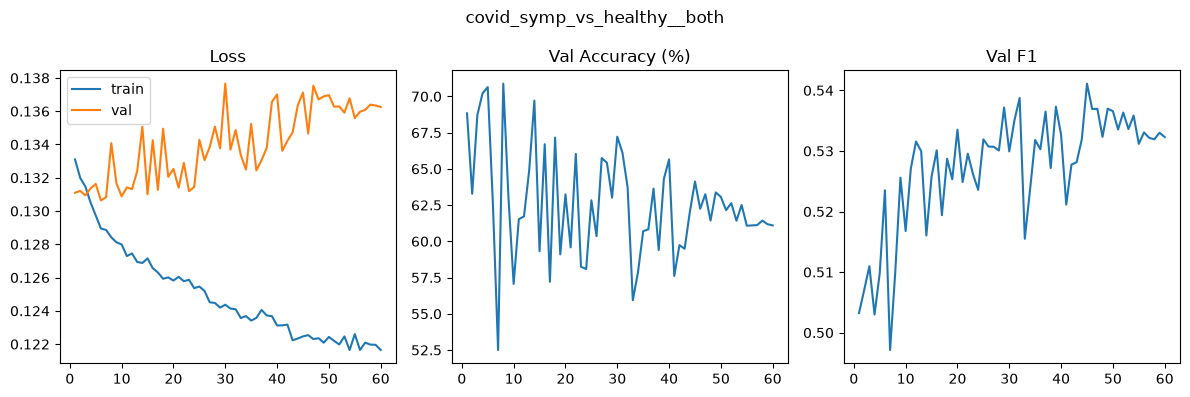

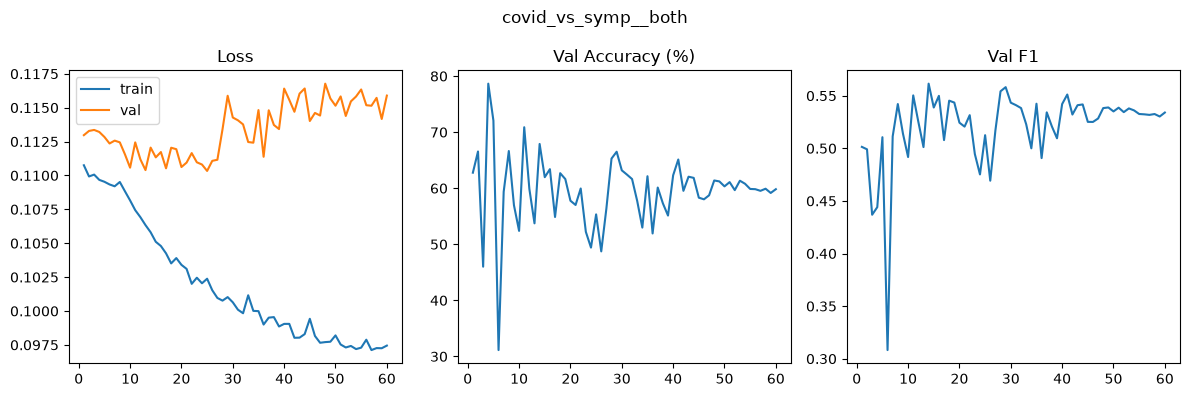

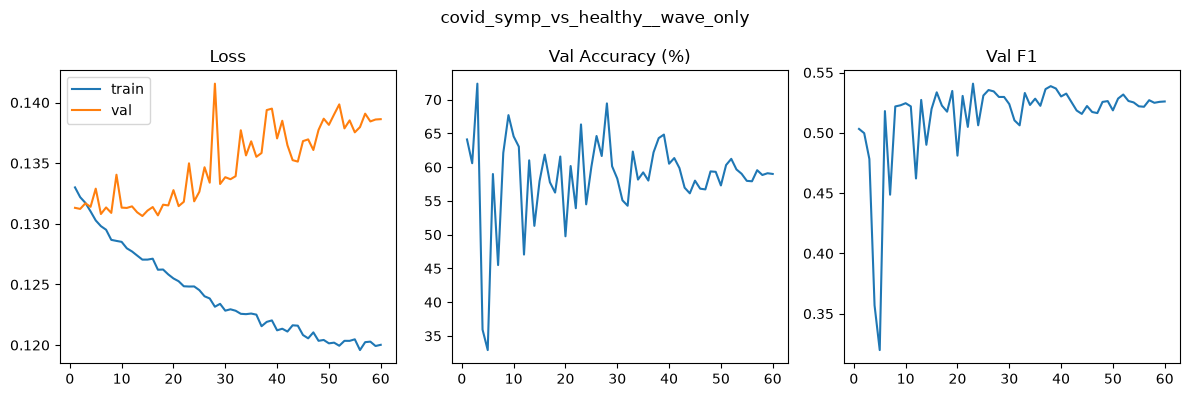

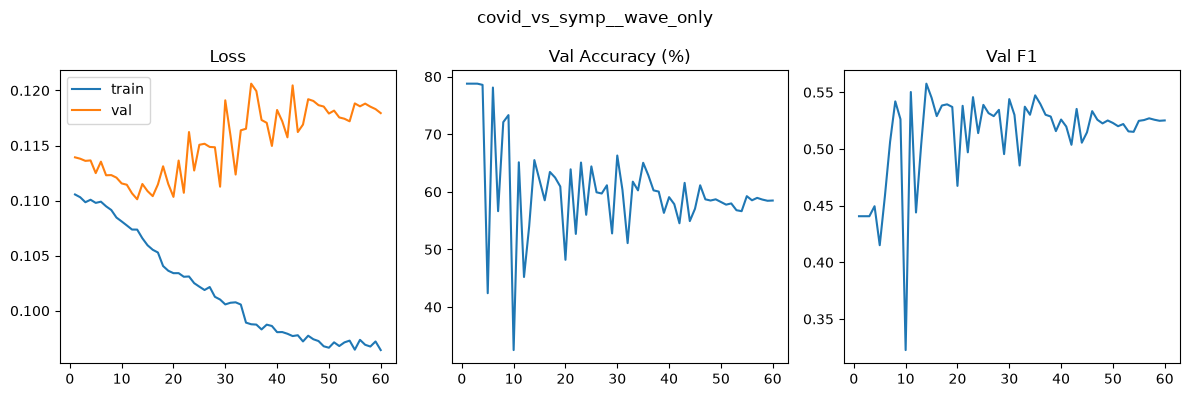

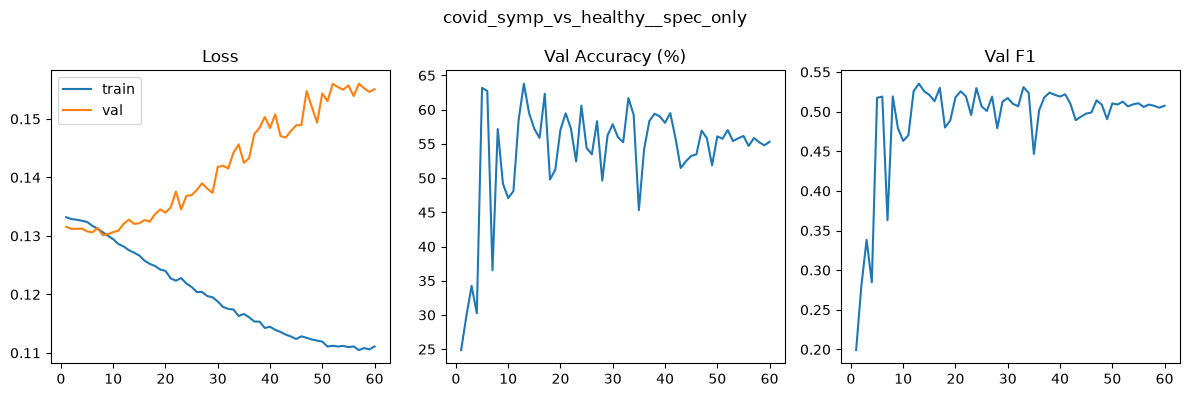

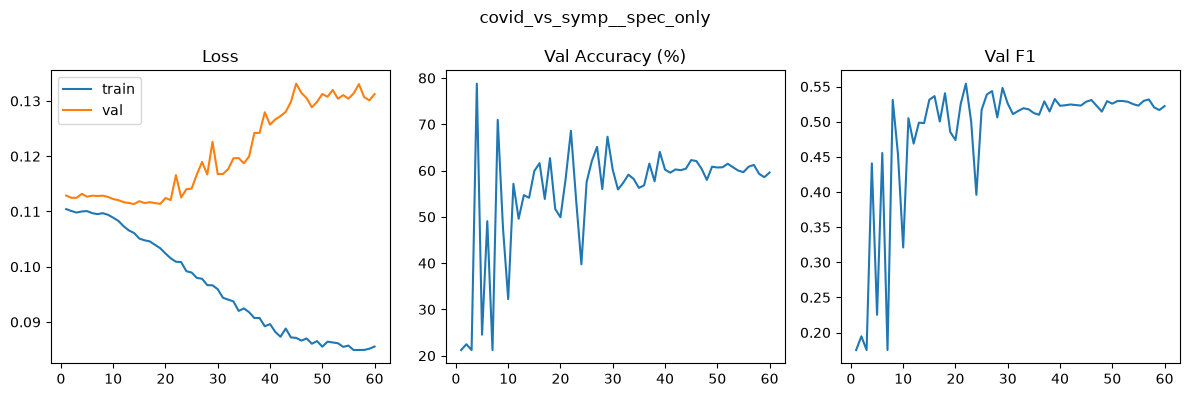

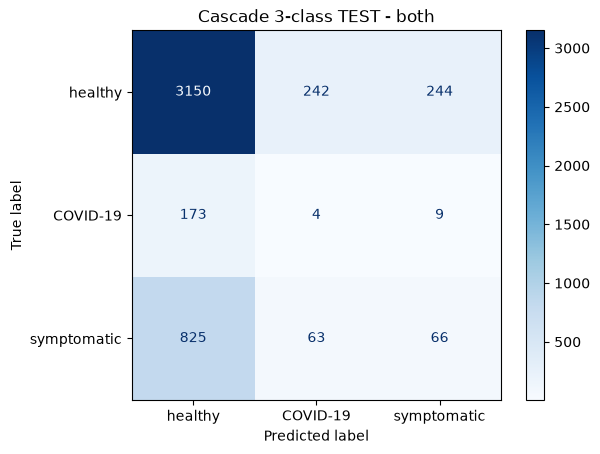

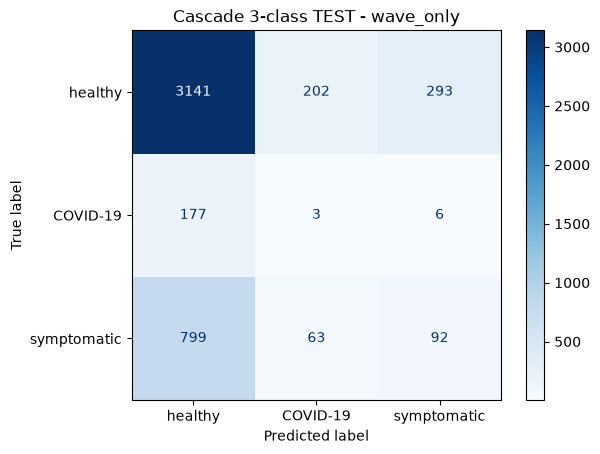

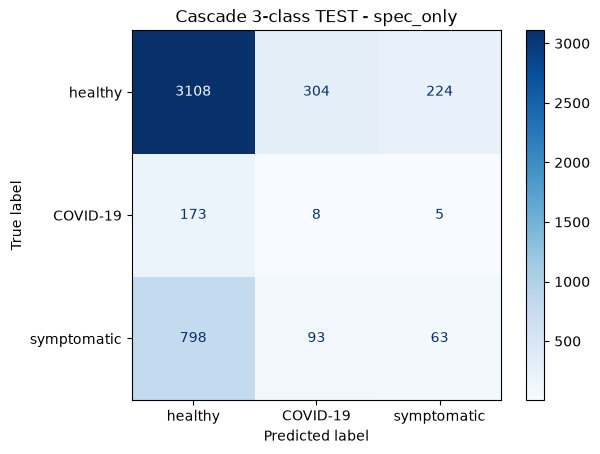

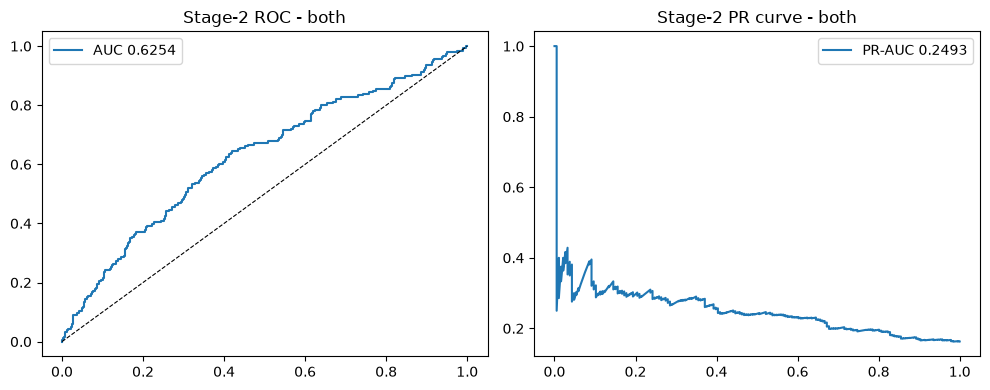

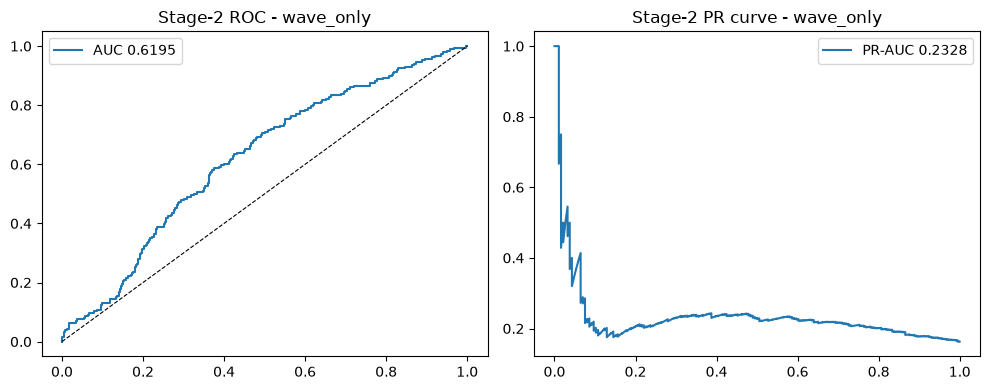

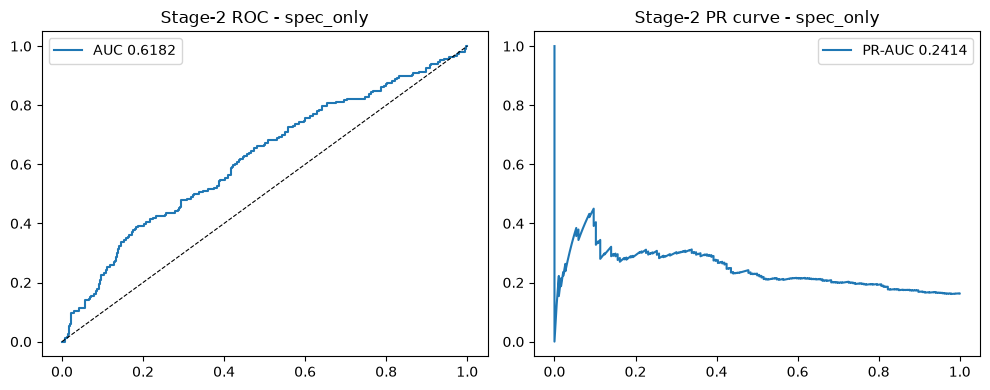

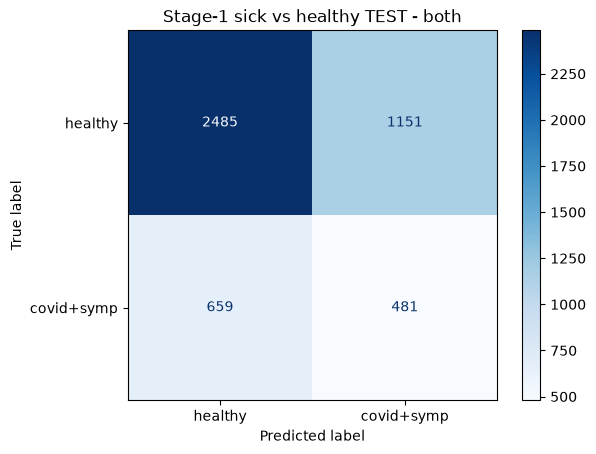

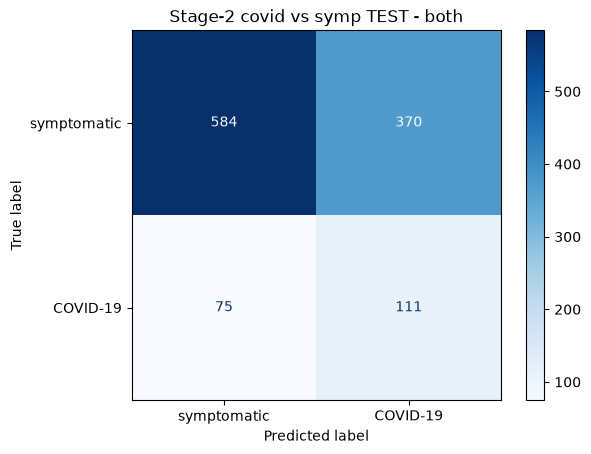

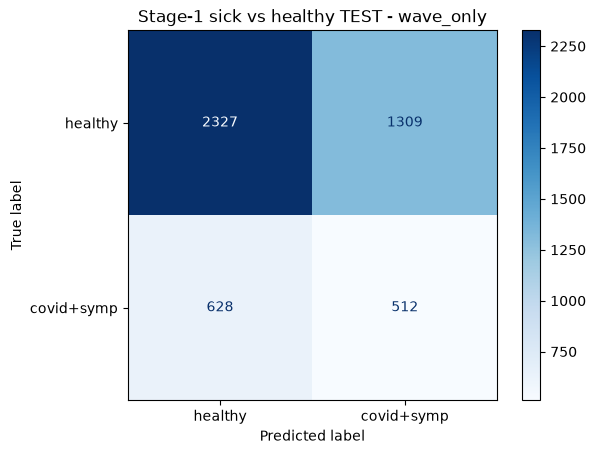

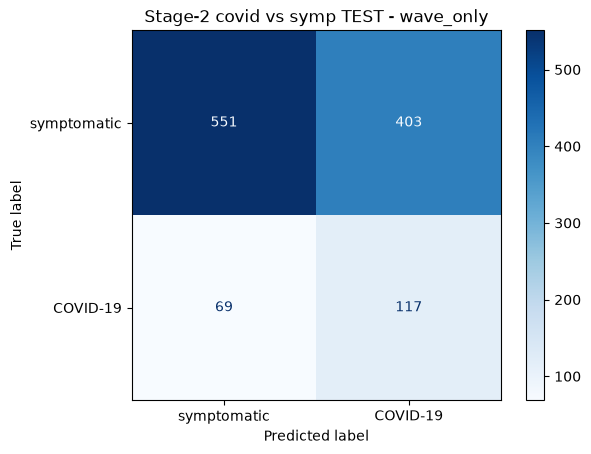

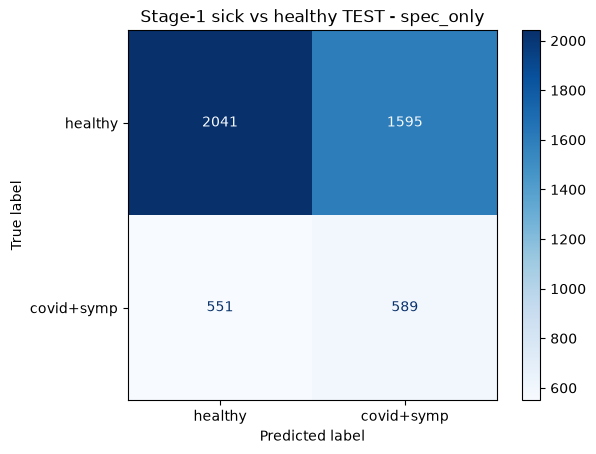

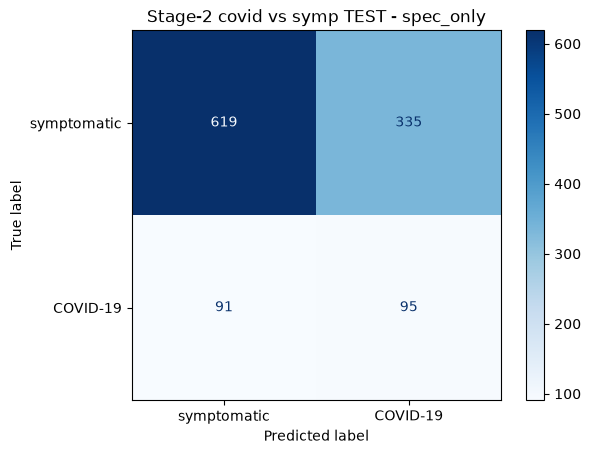

In [22]:

# ---- Cascade plots + tables: histories, CMs, ROC/PR curves, summary ----
import os, matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True)

# crash recovery: histories from CSVs, preds/curves from eval state
if "cascade_results" not in globals() or not cascade_results:
    cascade_results = {}
    for key in [f"{t}__{c}" for t in ("covid_symp_vs_healthy", "covid_vs_symp")
                for c in ("both", "wave_only", "spec_only")]:
        csv = f"{key}_experiment_stats.csv"
        if os.path.exists(csv):
            df = pl.read_csv(csv)
            cascade_results[key] = {col: df[col].to_list() for col in CSV_COLS}
    print("=> cascade_results rebuilt from *_experiment_stats.csv")

if "cascade_preds" not in globals():
    _evp = "run_state/cascade_eval_state.pt"
    assert os.path.exists(_evp), "run_state/cascade_eval_state.pt missing — run the eval cell first"
    _ev = torch.load(_evp, weights_only=False)
    cascade_preds, test_y3 = _ev["cascade_preds"], _ev["test_y3"]
    cascade_eval_rows = _ev["cascade_eval_rows"]
    stage2_standalone = _ev["stage2_standalone"]
    cascade_curves = _ev.get("curves", {})
    print("=> cascade eval state restored from run_state/cascade_eval_state.pt")

# history plots
for key, hist in cascade_results.items():
    fig, (ax_loss, ax_acc, ax_f1) = plt.subplots(1, 3, figsize=(12, 4))
    fig.suptitle(key)
    epochs = range(1, len(hist["train_loss"]) + 1)
    ax_loss.plot(epochs, hist["train_loss"], label="train")
    ax_loss.plot(epochs, hist["val_loss"], label="val")
    ax_loss.set_title("Loss"); ax_loss.legend()
    ax_acc.plot(epochs, hist["val_acc"]); ax_acc.set_title("Val Accuracy (%)")
    ax_f1.plot(epochs, hist["val_F1"]); ax_f1.set_title("Val F1")
    fig.tight_layout()
    fig.savefig(f"figures/{key}_history.png", bbox_inches="tight")
    plt.show(fig)
    plt.close(fig)

# combined 3-class cascade CMs
for cfg_name, pred3 in cascade_preds.items():
    cm3 = confusion_matrix(test_y3, pred3, labels=[0, 1, 2])
    disp = ConfusionMatrixDisplay(cm3, display_labels=list(LABELS_INV.values()))
    disp.plot(cmap="Blues")
    plt.title(f"Cascade 3-class TEST - {cfg_name}")
    plt.savefig(f"figures/cascade_3class_{cfg_name}.png", bbox_inches="tight")
    plt.show()
    plt.close("all")

# stage-2 ROC + PR curves from persisted curve data
for cfg_name, cur in cascade_curves.items():
    fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(10, 4))
    ax_roc.plot(cur["roc_fpr"], cur["roc_tpr"], label=f"AUC {stage2_standalone[[r['experiment'] for r in stage2_standalone].index(f'covid_vs_symp__{cfg_name}')]['test_roc_auc']}")
    ax_roc.plot([0, 1], [0, 1], "k--", lw=0.8); ax_roc.set_title(f"Stage-2 ROC - {cfg_name}"); ax_roc.legend()
    ax_pr.plot(cur["pr_rec"], cur["pr_prec"], label=f"PR-AUC {stage2_standalone[[r['experiment'] for r in stage2_standalone].index(f'covid_vs_symp__{cfg_name}')]['test_pr_auc']}")
    ax_pr.set_title(f"Stage-2 PR curve - {cfg_name}"); ax_pr.legend()
    fig.tight_layout()
    fig.savefig(f"figures/stage2_covid_vs_symp_{cfg_name}_curves.png", bbox_inches="tight")
    plt.show(fig)
    plt.close(fig)

# stage-1/stage-2 binary CMs (needs collect_probs + splits in memory)
if "collect_probs" not in globals() or "test_subset" not in globals() or "cascade_models" not in globals():
    print("=> skipping stage CM plots: collect_probs/test_subset/cascade_models not in memory — run the trainer/eval cells first")
else:
    for cfg_name, _, _ in CONFIGS:
        m1 = cascade_models[cfg_name]["stage1"]
        tp1, ty1 = collect_probs(m1, test_subset.indices, positive=-1, task="covid_symp_vs_healthy")
        _, vy1 = collect_probs(m1, val_subset.indices, positive=-1, task="covid_symp_vs_healthy")
        tau = tune_threshold(vy1, tp1)
        p1 = (tp1 >= tau).astype(int)
        cm = confusion_matrix(ty1, p1, labels=[0, 1])
        print(f"Stage-1 sick-vs-healthy TEST [{cfg_name}] tau={tau:.3f}  (rows=true [healthy, covid+symp])")
        print(cm)
        disp = ConfusionMatrixDisplay(cm, display_labels=["healthy", "covid+symp"])
        disp.plot(cmap="Blues")
        plt.title(f"Stage-1 sick vs healthy TEST - {cfg_name}")
        plt.savefig(f"figures/stage1_covid_symp_vs_healthy_{cfg_name}_cm.png", bbox_inches="tight")
        plt.show()
        plt.close("all")

        m2 = cascade_models[cfg_name]["stage2"]
        tp2, ty2 = collect_probs(m2, sick_test_idx, positive=1, task="covid_vs_symp")
        _, vy2 = collect_probs(m2, sick_val_idx, positive=1, task="covid_vs_symp")
        tau = tune_threshold(vy2, tp2)
        p2 = (tp2 >= tau).astype(int)
        cm = confusion_matrix(ty2, p2, labels=[0, 1])
        print(f"Stage-2 covid-vs-symp TEST [{cfg_name}] tau={tau:.3f}  (rows=true [symptomatic, COVID-19])")
        print(cm)
        disp = ConfusionMatrixDisplay(cm, display_labels=["symptomatic", "COVID-19"])
        disp.plot(cmap="Blues")
        plt.title(f"Stage-2 covid vs symp TEST - {cfg_name}")
        plt.savefig(f"figures/stage2_covid_vs_symp_{cfg_name}_cm.png", bbox_inches="tight")
        plt.show()
        plt.close("all")

# summary table: training histories, same format as results_table
pl.Config.set_ascii_tables()  # ponytail: cp1252 console can't render polars box chars
results_table(cascade_results).write_csv("cascade_experiment_summary.csv")

# eval results as printed tables
print("\n=== Cascade 3-class eval ===")
with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=200):
    print(pl.DataFrame(cascade_eval_rows))
    print("\n=== Stage-2 standalone eval ===")
    print(pl.DataFrame(stage2_standalone))
print("All figures + CSVs written to figures/ and notebook root.")

In [17]:
# ---- Save cascade history plots to figures/ ----
import matplotlib.pyplot as plt
import os
os.makedirs("figures", exist_ok=True)

# crash recovery: everything below restores from disk so plots work on a fresh kernel
if "cascade_results" not in globals() or not cascade_results:
    cascade_results = {}
    for key in [f"{t}__{c}" for t in ("covid_symp_vs_healthy", "covid_vs_symp")
                for c in ("both", "wave_only", "spec_only")]:
        csv = f"{key}_experiment_stats.csv"
        assert os.path.exists(csv), f"{csv} missing — run the training cells first"
        df = pl.read_csv(csv)
        cascade_results[key] = {col: df[col].to_list() for col in CSV_COLS}
    print("=> cascade_results rebuilt from *_experiment_stats.csv")

if "cascade_preds" not in globals():
    _evp = "run_state/cascade_eval_state.pt"
    assert os.path.exists(_evp), "run_state/cascade_eval_state.pt missing — run the eval cell first"
    _ev = torch.load(_evp, weights_only=False)
    cascade_preds, test_y3 = _ev["cascade_preds"], _ev["test_y3"]
    print("=> cascade_preds/test_y3 restored from run_state/cascade_eval_state.pt")

if "cascade_models" not in globals() or not cascade_models:
    # models restored straight from per-experiment checkpoints (no training).
    # checkpoints were saved from torch.compile'd models -> keys carry the
    # "_orig_mod." prefix, so wrap in compile before load_state_dict in that case.
    cascade_models = {}
    for cfg_name, _, _ in CONFIGS:
        for stage, key in [("stage1", f"covid_symp_vs_healthy__{cfg_name}"),
                           ("stage2", f"covid_vs_symp__{cfg_name}")]:
            path = _ckpt_path(key)
            assert os.path.exists(path), f"{path} missing — run the training cells first"
            ckpt = torch.load(path, weights_only=True, map_location=device)
            m = DefaultCNN(num_classes=2).to(device)
            if any(k.startswith("_orig_mod.") for k in ckpt["model_state_dict"]):
                m = torch.compile(m)
            m.load_state_dict(ckpt["model_state_dict"])
            m.eval()
            cascade_models.setdefault(cfg_name, {})[stage] = m
    print("=> cascade_models restored from run_state checkpoints")

for key in ["covid_symp_vs_healthy", "covid_vs_symp"]:
    for cfg_name, _, _ in CONFIGS:
        hist = cascade_results[f"{key}__{cfg_name}"]
        fig, (ax_loss, ax_acc, ax_f1) = plt.subplots(1, 3, figsize=(12, 4))
        fig.suptitle(f"{key} / {cfg_name}")
        epochs = range(1, len(hist["train_loss"]) + 1)
        ax_loss.plot(epochs, hist["train_loss"], label="train")
        ax_loss.plot(epochs, hist["val_loss"], label="val")
        ax_loss.set_title("Loss"); ax_loss.legend()
        ax_acc.plot(epochs, hist["val_acc"]); ax_acc.set_title("Val Accuracy (%)")
        ax_f1.plot(epochs, hist["val_F1"]); ax_f1.set_title("Val F1")
        fig.tight_layout()
        fig.savefig(f"figures/{key}__{cfg_name}_history.png", bbox_inches="tight")
        plt.show(fig)
        plt.close(fig)

# combined 3-class cascade confusion matrices
for cfg_name in cascade_preds:
    cm3 = confusion_matrix(test_y3, cascade_preds[cfg_name], labels=[0, 1, 2])
    disp = ConfusionMatrixDisplay(cm3, display_labels=list(LABELS_INV.values()))
    disp.plot(cmap="Blues")
    plt.title(f"Cascade 3-class TEST - {cfg_name}")
    plt.savefig(f"figures/cascade_3class_{cfg_name}.png", bbox_inches="tight")
    plt.show()
    plt.close("all")

# ---- Stage-1/Stage-2 binary confusion matrices on TEST ----
# These need collect_probs (defined with train_binary) + the split subsets in
# memory. Everything above works from persisted state alone; skip with a note
# if this cell runs standalone on a fresh kernel.
if "collect_probs" not in globals() or "test_subset" not in globals():
    print("=> skipping stage-1/stage-2 CM plots: collect_probs/test_subset not in memory — run the train_binary definition + split cells first")
else:
    for cfg_name, _, _ in CONFIGS:
        m1 = cascade_models[cfg_name]["stage1"]
        tp1, ty1 = collect_probs(m1, test_subset.indices, positive=-1, task="covid_symp_vs_healthy")
        _, vy1 = collect_probs(m1, val_subset.indices, positive=-1, task="covid_symp_vs_healthy")
        tau = tune_threshold(vy1, tp1)
        p1 = (tp1 >= tau).astype(int)
        cm = confusion_matrix(ty1, p1, labels=[0, 1])
        print(f"Stage-1 sick-vs-healthy TEST [{cfg_name}] tau={tau:.3f}")
        print("rows=true [healthy, covid+symp], cols=pred")
        print(cm)
        disp = ConfusionMatrixDisplay(cm, display_labels=["healthy", "covid+symp"])
        disp.plot(cmap="Blues")
        plt.title(f"Stage-1 sick vs healthy TEST - {cfg_name}")
        plt.savefig(f"figures/stage1_covid_symp_vs_healthy_{cfg_name}_cm.png", bbox_inches="tight")
        plt.show()
        plt.close("all")

    for cfg_name, _, _ in CONFIGS:
        m2 = cascade_models[cfg_name]["stage2"]
        tp2, ty2 = collect_probs(m2, sick_test_idx, positive=1, task="covid_vs_symp")
        _, vy2 = collect_probs(m2, sick_val_idx, positive=1, task="covid_vs_symp")
        tau = tune_threshold(vy2, tp2)
        p2 = (tp2 >= tau).astype(int)
        cm = confusion_matrix(ty2, p2, labels=[0, 1])
        print(f"Stage-2 covid-vs-symp TEST [{cfg_name}] tau={tau:.3f}")
        print("rows=true [symptomatic, COVID-19], cols=pred")
        print(cm)
        disp = ConfusionMatrixDisplay(cm, display_labels=["symptomatic", "COVID-19"])
        disp.plot(cmap="Blues")
        plt.title(f"Stage-2 covid vs symp TEST - {cfg_name}")
        plt.savefig(f"figures/stage2_covid_vs_symp_{cfg_name}_cm.png", bbox_inches="tight")
        plt.show()
        plt.close("all")

AssertionError: run_state/cascade_eval_state.pt missing — run the eval cell first

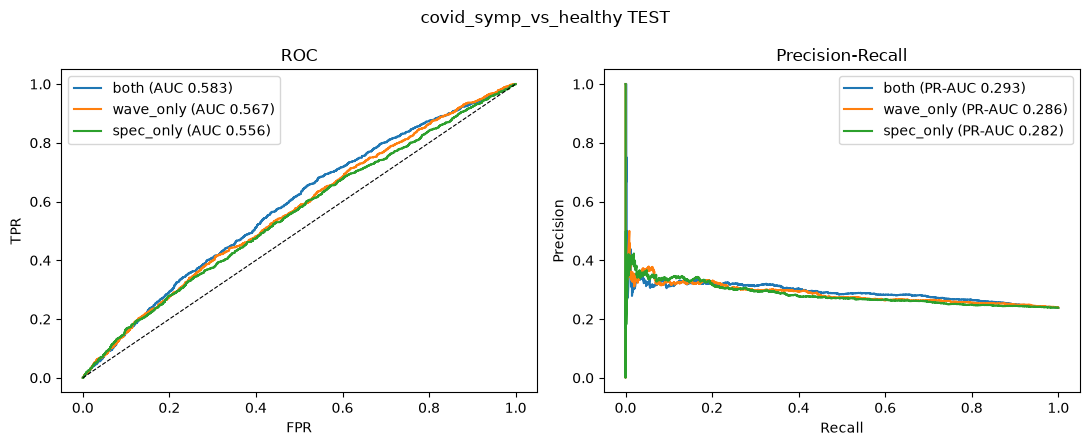

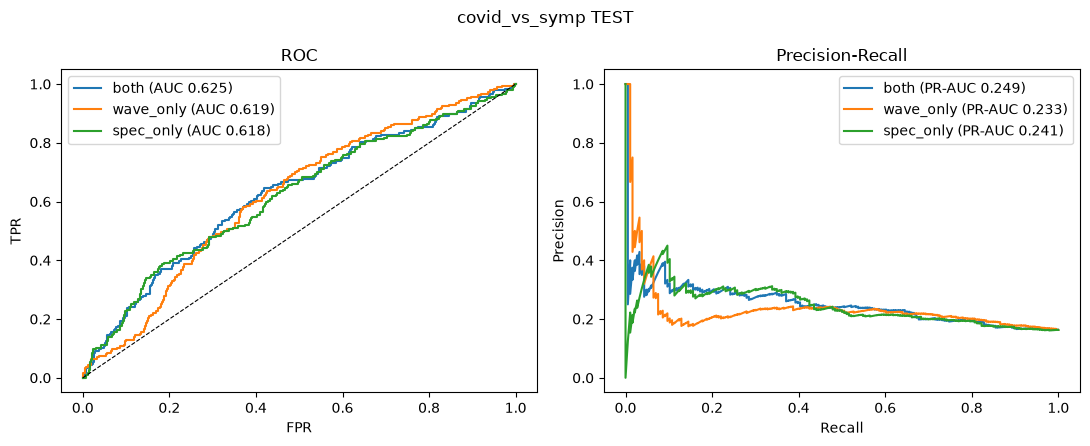

In [18]:
# ---- Paper outputs: ROC + PR curves per task/config, comparison figure ----
from sklearn.metrics import roc_curve

# ROC + PR curves, one figure per task, one line per config
# These need collect_probs + splits in memory (fresh inference pass); skip with
# a note on a standalone fresh kernel — the PNGs from the full run stay in figures/.
if "collect_probs" not in globals() or "test_subset" not in globals():
    print("=> skipping ROC/PR curves: collect_probs/test_subset not in memory — run the train_binary definition + split cells first")
else:
    for task, indices in [
        ("covid_symp_vs_healthy", test_subset.indices),
        ("covid_vs_symp", sick_test_idx),
    ]:
        fig, (ax_r, ax_p) = plt.subplots(1, 2, figsize=(11, 4.5))
        fig.suptitle(f"{task} TEST")
        for cfg_name, _, _ in CONFIGS:
            model = cascade_models[cfg_name]["stage1" if task == "covid_symp_vs_healthy" else "stage2"]
            probs, y = collect_probs(model, indices, positive=1, task=task)
            fpr, tpr, _ = roc_curve(y, probs)
            pr, pr_t, _ = precision_recall_curve(y, probs)
            ax_r.plot(fpr, tpr, label=f"{cfg_name} (AUC {roc_auc_score(y, probs):.3f})")
            ax_p.plot(pr_t, pr, label=f"{cfg_name} (PR-AUC {auc(pr_t, pr):.3f})")
        ax_r.plot([0, 1], [0, 1], "k--", lw=0.8)
        ax_r.set_xlabel("FPR"); ax_r.set_ylabel("TPR"); ax_r.set_title("ROC")
        ax_p.set_xlabel("Recall"); ax_p.set_ylabel("Precision"); ax_p.set_title("Precision-Recall")
        ax_r.legend(); ax_p.legend()
        fig.tight_layout()
        fig.savefig(f"figures/{task}_test_curves.png", bbox_inches="tight")
        plt.show(fig)
        plt.close(fig)


print("All paper figures + CSVs written to figures/ and notebook root.")

In [15]:
def results_table(results: dict[str, dict[str, list[float]]]) -> None:
    """Summary table per experiment: max / min / final / avg / std of each metric."""

    rows: list[dict] = []
    for name, hist in results.items():
        for metric in ("train_loss", "val_loss", "val_acc"):
            vals: list[float] = hist[metric]
            rows.append({
                "experiment": name,
                "metric": metric,
                "max": round(max(vals), 4),
                "min": round(min(vals), 4),
                "final": round(vals[-1], 4),
                "avg": round(sum(vals) / len(vals), 4),
                "std": round(float(np.std(vals)), 4),
            })
    df = pl.DataFrame(rows)
    pl.Config.set_ascii_tables()  # ponytail: cp1252 console can't render polars box chars
    with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=120):
        print(df)
    return df


In [14]:
# ==== Multi-model training (DefaultCNN / BranchedCoughCNN / ResNet50 finetune) ====
# Appended block: config, trainer, training loop, eval, plots — new cells at the end.
# Existing cascade cells above are untouched.
from modules.nn.base_nn import ResNetModel  # extra import for this block

# pick model + augmentation BY STRING before running:
# model: "default" | "branched" | "resnet"   aug: "both" | "wave_only" | "spec_only"
TRAINED_CONFIGS: dict[str, list[str]] = {
    "default":  ["both", "wave_only", "spec_only"],
    "branched": ["both", "wave_only", "spec_only"],
    "resnet":   ["both", "wave_only", "spec_only"],
}
AUG_MAP: dict[str, tuple[bool, bool]] = {"both": (True, True), "wave_only": (True, False), "spec_only": (False, True)}
MODEL_PATIENCE: int = 20  # early stop: val_loss plateau of this many epochs
TRAINED_RUNS: list[tuple[str, str]] = [("default", "both"), ("branched", "both"), ("resnet", "both")]
print("Runs scheduled:", [f"{mn}/{cfg}" for mn, cfg in TRAINED_RUNS])

# separate spec/mfcc streams for the branched model (forward returns (spec, mfcc))
mel_train_plain_sep: SpectMFCCPipeline = SpectMFCCPipeline(combind=False).to(device)
mel_train_spec_sep: SpectMFCCPipeline = SpectMFCCPipeline(transforms=SpecAugmentations(), combind=False).to(device)
mel_eval_sep: SpectMFCCPipeline = SpectMFCCPipeline(combind=False).to(device)
mel_eval_sep = torch.compile(mel_eval_sep) if device.type == "cuda" else mel_eval_sep

Runs scheduled: ['default/both', 'branched/both', 'resnet/both']


In [17]:
# ---- Multi-model trainer: same checkpointing/resume as train_binary, plus
# model-by-string, best-checkpoint saves, and early stop on val_loss plateaus ----
def _make_model(model_name: str, num_classes: int = 2) -> nn.Module:
    """Model factory by string. resnet = ResNet50 ImageNet weights, head swapped, full finetune."""
    if model_name == "default":
        return DefaultCNN(num_classes)
    if model_name == "branched":
        return BranchedCoughCNN(num_classes)
    if model_name == "resnet":
        return ResNetModel(num_classes, freeze_backbone=False)
    raise ValueError(f"unknown model_name {model_name!r} (default|branched|resnet)")

def _ckpt_best_path(name: str) -> str:
    return os.path.join(RUN_STATE_DIR, f"{name}_best.pth.tar")

def _resume_with_best(name: str, model: nn.Module, optimizer: optim.Optimizer,
                      scheduler: optim.lr_scheduler.LRScheduler,
                      scaler: torch.amp.GradScaler, num_epochs: int) -> tuple[int, dict, float, int]:
    """Load _latest checkpoint into model/opt/sched/scaler; derive best val_loss
    and trailing plateau length from history. Returns (epochs_done, history, best_vl, plateau)."""
    best_vl, plate = float("inf"), 0
    path = _ckpt_path(name)
    if not os.path.exists(path):
        return 0, {"train_loss": [], "val_loss": [], "val_acc": [], "val_F1": [], "val_auc": [], "val_pr_auc": []}, best_vl, plate
    ckpt = torch.load(path, weights_only=True, map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    scheduler.load_state_dict(ckpt["scheduler_state_dict"])
    scaler.load_state_dict(ckpt["scaler_state_dict"])
    epochs_done: int = ckpt["epoch"] + 1
    history: dict[str, list[float]] = ckpt["history"]
    if history["val_loss"]:
        best_vl = min(history["val_loss"])
        for vl in reversed(history["val_loss"]):
            if vl <= best_vl + 1e-6:
                break
            plate += 1
    if epochs_done >= num_epochs:
        trained_models[name] = model
    print(f"=> [{name}] resumed at epoch {epochs_done + 1}/{num_epochs} (best val_loss {best_vl:.4f})" if epochs_done < num_epochs
          else f"=> [{name}] already complete ({num_epochs}/{num_epochs} epochs) — restored, no retrain")
    return epochs_done, history, best_vl, plate

def _collect_probs_mn(model: nn.Module, mn: str, indices: Sequence[int], positive: int,
                      task: str | None = None) -> tuple[np.ndarray, np.ndarray]:
    """collect_probs generalized per model: branched takes separate (spec, mfcc)
    streams; default/resnet take the combined 3-channel image."""
    use_sep = (mn == "branched")
    if task is not None:
        task_ds = TaskDataset(dataset, task)
        pos = task_ds.positions_for(list(indices))
        src = task_ds
    else:
        pos = list(indices)
        src = dataset
    loader = torch.utils.data.DataLoader(
        Subset(src, pos), BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
    probs: list[float] = []
    targets: list[int] = []
    model.eval()
    with torch.inference_mode():
        for waveforms, labels in loader:
            waveforms = waveforms.to(device, non_blocking=True)
            raw = labels.long()
            if use_sep:
                spec, mfcc = mel_eval_sep(waveforms)
                if spec.ndim == 3:
                    spec, mfcc = spec.unsqueeze(0), mfcc.unsqueeze(0)
                outputs = model(spec, mfcc)
            else:
                images = mel_eval(waveforms)
                if images.ndim == 3:
                    images = images.unsqueeze(0)
                outputs = model(images)
            probs.extend(torch.softmax(outputs, dim=1)[:, 1].cpu().numpy())
            if task is not None:
                t = TASK_TARGETS[task](raw)
            else:
                t = binary_labels(raw, positive)
            targets.extend(t.numpy())
    return np.array(probs), np.array(targets)

def train_model(name: str, positive: int, use_wave: bool, use_spec: bool,
                model_name: str = "default", num_epochs: int = 100,
                positives: frozenset[int] | None = None,
                task: str | None = None,
                patience: int = 20) -> dict[str, list[float]]:
    """train_binary generalized: model by string, best-checkpoint saves,
    early stop when val_loss stalls for `patience` epochs. Crash-proof identical."""
    history: dict[str, list[float]] = {"train_loss": [], "val_loss": [], "val_acc": [], "val_F1": [], "val_auc": [], "val_pr_auc": []}

    if task is not None:
        task_ds = TaskDataset(dataset, task)
        have = set(task_ds.indices)
        tr_base = [i for i in train_subset.indices if i in have]
        va_base = [i for i in val_subset.indices if i in have]
        tr_pos = task_ds.positions_for(tr_base)
        va_pos = task_ds.positions_for(va_base)
        tgt = TASK_TARGETS[task](dataset.labels[torch.tensor(tr_base)])
        n_pos = int(tgt.sum()); n_neg = len(tgt) - n_pos
        w = 1.0 / torch.tensor([n_neg, n_pos], dtype=torch.float32).clamp(min=1)
    else:
        tr_idx, va_idx = train_subset.indices, val_subset.indices
        if positives is not None:
            in_group = torch.isin(train_labels, torch.tensor(sorted(positives)))
            counts = torch.tensor([(~in_group).sum(), in_group.sum()]).float()
        else:
            counts = torch.bincount(train_labels, minlength=3).float()
            counts = torch.tensor([counts.sum() - counts[positive], counts[positive]])
        w = 1.0 / counts.clamp(min=1)
    w = w / w.sum() * 2.0  # normalize so mean weight is 1 (keeps loss scale comparable)
    w = w.to(device)

    criterion: nn.Module = FocalLoss(alpha=w, gamma=2.0)

    m = _make_model(model_name)
    if device.type == "cuda":
        model: nn.Module = torch.compile(m).to(device)
    else:
        model = m.to(device)

    optimizer: optim.AdamW = optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-2)
    scaler: torch.amp.GradScaler = torch.amp.GradScaler(enabled=(device.type == "cuda"))
    scheduler: optim.lr_scheduler.CosineAnnealingLR = optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=num_epochs, eta_min=1e-6
    )

    epochs_done, history, best_val_loss, plateau = _resume_with_best(
        name, model, optimizer, scheduler, scaler, num_epochs)

    use_sep: bool = (model_name == "branched")
    mel_train = (mel_train_spec_sep if use_spec else mel_train_plain_sep) if use_sep else (mel_train_spec if use_spec else mel_train_plain)

    if task is not None:
        tr_src, va_src = task_ds, task_ds
    else:
        tr_src = va_src = dataset

    train_ds: AugmentedSubset | Subset = AugmentedSubset(
        tr_src, tr_pos if task is not None else tr_idx,
        WaveformAugmentor(16_000)
    ) if use_wave else Subset(tr_src, tr_pos if task is not None else tr_idx)

    train_loader: torch.utils.data.DataLoader = torch.utils.data.DataLoader(
        train_ds, BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True,
        persistent_workers=True, prefetch_factor=4,
    )
    val_loader: torch.utils.data.DataLoader = torch.utils.data.DataLoader(
        Subset(va_src, va_pos if task is not None else va_idx), BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True,
        persistent_workers=True, prefetch_factor=4,
    )

    def relabel(raw: torch.Tensor) -> torch.Tensor:
        if task is not None:
            return TASK_TARGETS[task](raw)
        if positives is not None:
            return binary_labels_grouped(raw, positives)
        return binary_labels(raw, positive)

    def forward_features(waveforms: torch.Tensor, raw: torch.Tensor, mel):
        """Combined pipelines return one (B,3,F,T) image; separated return (spec, mfcc)."""
        feats = mel(waveforms, raw)
        if use_sep:
            spec, mfcc = feats
            if spec.ndim == 3:
                spec, mfcc = spec.unsqueeze(0), mfcc.unsqueeze(0)
            return spec, mfcc
        if feats.ndim == 3:
            feats = feats.unsqueeze(0)
        return feats

    for epoch in range(epochs_done, num_epochs):
        model.train()
        running_loss = 0.0

        for waveforms, labels in tqdm(train_loader, desc=f"[{name}] train {epoch+1}/{num_epochs}", leave=False):
            waveforms = waveforms.to(device, non_blocking=True)
            raw = labels.long().to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            feats = forward_features(waveforms, raw, mel_train)  # fp32 outside autocast (see train_binary note)
            target = relabel(raw)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                outputs = model(*feats) if use_sep else model(feats)
                loss = criterion(outputs, target)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            running_loss += loss.item()

        scheduler.step()

        model.eval()
        val_loss = 0.0
        correct = 0
        total = 0
        all_preds, all_targets, all_probs = [], [], []

        with torch.inference_mode():
            for waveforms, labels in tqdm(val_loader, desc=f"[{name}] val {epoch+1}/{num_epochs}", leave=False):
                waveforms = waveforms.to(device, non_blocking=True)
                raw = labels.long().to(device, non_blocking=True)
                feats = forward_features(waveforms, raw, mel_eval_sep if use_sep else mel_eval)
                target = relabel(raw)
                with torch.amp.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                    outputs = model(*feats) if use_sep else model(feats)
                    loss = criterion(outputs, target)
                all_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
                all_targets.extend(target.cpu().numpy())
                all_probs.extend(torch.softmax(outputs, dim=1)[:, 1].cpu().numpy())
                val_loss += loss.item()
                total += raw.size(0)
                correct += (torch.argmax(outputs, dim=1) == target).sum().item()

        val_macro_f1 = f1_score(all_targets, all_preds, average="macro")
        val_auc_score = roc_auc_score(all_targets, all_probs)
        pr_curve, pr_targets, _ = precision_recall_curve(all_targets, all_probs)
        val_pr = auc(pr_targets, pr_curve)
        train_epoch_loss = running_loss / len(train_loader)
        val_epoch_loss = val_loss / len(val_loader)
        val_accuracy = 100.0 * correct / total

        history["train_loss"].append(train_epoch_loss)
        history["val_loss"].append(val_epoch_loss)
        history["val_F1"].append(val_macro_f1)
        history["val_acc"].append(val_accuracy)
        history["val_auc"].append(val_auc_score)
        history["val_pr_auc"].append(val_pr)

        state = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "history": history,
        }
        _atomic_torch_save(state, _ckpt_path(name))
        if val_epoch_loss < best_val_loss - 1e-6:
            best_val_loss = val_epoch_loss
            plateau = 0
            _atomic_torch_save(state, _ckpt_best_path(name))  # best checkpoint on val_loss improvement
            print(f"=> [{name}] new best val_loss {best_val_loss:.4f} (epoch {epoch+1})")
        else:
            plateau += 1

        print(f"[{name}] Epoch [{epoch+1}/{num_epochs}] -> "
              f"Train Loss: {train_epoch_loss:.4f} | "
              f"Val Loss: {val_epoch_loss:.4f} | "
              f"Val F1: {val_macro_f1:.4f} | "
              f"Val AUC: {val_auc_score:.4f} | "
              f"Val PR-AUC: {val_pr:.4f} | "
              f"Val Acc: {val_accuracy:.2f}%")

        if plateau >= patience:
            print(f"=> [{name}] early stop: val_loss plateaued for {patience} epochs (best {best_val_loss:.4f})")
            break

    trained_models[name] = model
    return history

In [20]:
# ---- Multi-model training loop: 2-stage cascade x models x aug configs ----
# All outputs labeled trained_*. Seeds from disk (never wipes/KeyErrors on re-run),
# resumes mid-run, short-circuits finished runs.
import time, sys, atexit
LOG_PATH3 = r"logs/trained_models_experiment_2026-10-25.txt"
_logf3 = open(LOG_PATH3, "a", encoding="utf-8")
sys.stdout = _logf3
sys.stderr = _logf3
atexit.register(_logf3.close)



def seed_trained_state() -> tuple[dict, dict]:
    """Seed trained_results / trained_models_all from CSVs + checkpoints on disk
    (plus whatever is already in memory) so re-runs never wipe or KeyError."""
    results: dict[str, dict[str, list[float]]] = {}
    if "trained_results" in globals():
        results.update(trained_results)
    models_all: dict[str, dict] = {}
    if "trained_models_all" in globals():
        models_all.update(trained_models_all)
    for mn, cfg in TRAINED_RUNS:
        for stage, task in [("stage1", "covid_symp_vs_healthy"), ("stage2", "covid_vs_symp")]:
            key = f"{mn}__{task}__{cfg}"
            if key not in results and os.path.exists(f"trained_{key}_experiment_stats.csv"):
                df = pl.read_csv(f"trained_{key}_experiment_stats.csv")
                results[key] = {col: df[col].to_list() for col in CSV_COLS}
            if stage not in models_all.setdefault(mn, {}).setdefault(cfg, {}) and os.path.exists(_ckpt_path(key)):
                ckpt = torch.load(_ckpt_path(key), weights_only=True, map_location=device)
                m = _make_model(mn).to(device)
                # Lazy models need materialized params before load_state_dict
                with torch.inference_mode():
                    if mn == "branched":
                        s = torch.zeros(1, 3, 104, 32, device=device)
                        _ = m(s, s)
                    else:
                        _ = m(torch.zeros(1, 3, 104, 32, device=device))
                if any(k.startswith("_orig_mod.") for k in ckpt["model_state_dict"]):
                    m = torch.compile(m)
                m.load_state_dict(ckpt["model_state_dict"])
                m.eval()
                models_all[mn][cfg][stage] = m
    return results, models_all

trained_results, trained_models_all = seed_trained_state()
trained_stop_info: dict[str, str] = {}  # key -> "complete" | "early stop @ epoch N"

print("STARTING MULTI-MODEL EXPERIMENTS")
for mn, cfg in TRAINED_RUNS:
    uw, us = AUG_MAP[cfg]
    for stage_num, (stage, task, positive) in enumerate(
        [("stage1", "covid_symp_vs_healthy", -1), ("stage2", "covid_vs_symp", 1)], start=1
    ):
        key = f"{mn}__{task}__{cfg}"
        if key in trained_results and len(trained_results[key]["val_loss"]) >= num_epochs:
            print(f"\n--- {key} --- already complete, skipping (restored from disk)")
            continue
        print(f"\n--- {key} --- (stage {stage_num}: {task})")
        t0 = time.time()
        hist = train_model(key, positive=positive, use_wave=uw, use_spec=us, num_epochs=256,
                           model_name=mn, task=task, patience=MODEL_PATIENCE)
        trained_results[key] = hist
        pl.DataFrame({k: hist[k] for k in CSV_COLS}).write_csv(f"trained_{key}_experiment_stats.csv")
        trained_models_all.setdefault(mn, {}).setdefault(cfg, {})[stage] = trained_models[key]
        done = len(hist["val_loss"])
        trained_stop_info[key] = "complete" if done >= num_epochs else f"early stop @ epoch {done}"
        print(f"=> {key}: {done}/{num_epochs} epochs in {time.time() - t0:.0f}s — {trained_stop_info[key]}")

print("\n=== Multi-model training done ===")
for (mn, cfg) in TRAINED_RUNS:
    for task in ("covid_symp_vs_healthy", "covid_vs_symp"):
        key = f"{mn}__{task}__{cfg}"
        if key in trained_results:
            h = trained_results[key]
            print(f"{key:<44} {len(h['val_loss']):>3}/60 epochs  final val_acc {h['val_acc'][-1]:.2f}%")

[default__covid_symp_vs_healthy__both] train 1/256:   0%|          | 0/262 [00:27<?, ?it/s]

[default__covid_symp_vs_healthy__both] val 1/256:   0%|          | 0/75 [00:28<?, ?it/s]

[default__covid_symp_vs_healthy__both] train 2/256:   0%|          | 0/262 [00:00<?, ?it/s]

[default__covid_symp_vs_healthy__both] val 2/256:   0%|          | 0/75 [00:00<?, ?it/s]

[default__covid_symp_vs_healthy__both] train 3/256:   0%|          | 0/262 [00:00<?, ?it/s]

...

[resnet__covid_vs_symp__both] val 21/256:   0%|          | 0/19 [00:00<?, ?it/s]

[resnet__covid_vs_symp__both] train 22/256:   0%|          | 0/68 [00:00<?, ?it/s]

[resnet__covid_vs_symp__both] val 22/256:   0%|          | 0/19 [00:00<?, ?it/s]

[resnet__covid_vs_symp__both] train 23/256:   0%|          | 0/68 [00:00<?, ?it/s]

[resnet__covid_vs_symp__both] val 23/256:   0%|          | 0/19 [00:00<?, ?it/s]

In [18]:
if "trained_results" not in globals() or not trained_results:
    trained_results: dict[str, dict[str, list[float]]] = {}
    for mn, cfg in TRAINED_RUNS:
        for task in ("covid_symp_vs_healthy", "covid_vs_symp"):
            key = f"{mn}__{task}__{cfg}"
            csv = f"trained_{key}_experiment_stats.csv"
            if os.path.exists(csv):
                df = pl.read_csv(csv)
                trained_results[key] = {col: df[col].to_list() for col in CSV_COLS}
    print(f"=> trained_results rebuilt from CSVs ({len(trained_results)} runs)")

if "trained_models_all" not in globals() or not trained_models_all:
    trained_models_all: dict[str, dict] = {}
    for mn, cfg in TRAINED_RUNS:
        for stage, task in [("stage1", "covid_symp_vs_healthy"), ("stage2", "covid_vs_symp")]:
            key = f"{mn}__{task}__{cfg}"
            path = _ckpt_path(key)
            if not os.path.exists(path):
                print(f"!! {path} missing — skipping {key}")
                continue
            ckpt = torch.load(path, weights_only=True, map_location=device)
            m = _make_model(mn).to(device)
            with torch.inference_mode():  # materialize lazy params before load
                if mn == "branched":
                    s = torch.zeros(1, 3, 104, 32, device=device)
                    _ = m(s, s)
                else:
                    _ = m(torch.zeros(1, 3, 104, 32, device=device))
            if any(k.startswith("_orig_mod.") for k in ckpt["model_state_dict"]):
                m = torch.compile(m)
            m.load_state_dict(ckpt["model_state_dict"])
            m.eval()
            trained_models_all.setdefault(mn, {}).setdefault(cfg, {})[stage] = m
    print("=> trained_models_all restored from run_state checkpoints")

# eval cell's condition is `"trained_preds" in globals() and trained_models_all`
# (membership check, not truthiness) — an empty dict is enough to trigger the
# fresh eval pass, which then assigns the real predictions itself.
trained_preds: dict[str, np.ndarray] = {}
print("=> setup done: trained_preds placeholder set, eval cell can run")

=> trained_models_all restored from run_state checkpoints
=> setup done: trained_preds placeholder set, eval cell can run


In [19]:
# ---- Multi-model cascade eval: thresholds + 3-class decision on TEST ----
# Mirrors the cascade eval cell for every trained_{model} run.
# Persists to run_state/trained_eval_state.pt so a fresh kernel skips the eval pass.
def _save_trained_eval(obj: dict) -> None:
    tmp = "run_state/trained_eval_state.pt.tmp"
    torch.save(obj, tmp)
    os.replace(tmp, "run_state/trained_eval_state.pt")

def _load_trained_eval() -> dict | None:
    p = "run_state/trained_eval_state.pt"
    return torch.load(p, weights_only=False) if os.path.exists(p) else None

if "trained_preds" in globals() and trained_models_all:
    # fresh eval pass (models in memory from training)
    trained_preds: dict[str, np.ndarray] = {}
    trained_eval_rows: list[dict] = []
    trained_stage2_rows: list[dict] = []

    test_y3_t = np.array([int(dataset.labels[i]) for i in test_subset.indices])

    for mn, cfg in TRAINED_RUNS:
        key1, key2 = f"{mn}__covid_symp_vs_healthy__{cfg}", f"{mn}__covid_vs_symp__{cfg}"
        if key1 not in trained_results:
            continue
        m1 = trained_models_all[mn][cfg]["stage1"]
        m2 = trained_models_all[mn][cfg]["stage2"]

        val_probs1, val_y1 = _collect_probs_mn(m1, mn, val_subset.indices, positive=-1, task="covid_symp_vs_healthy")
        tau_sick = tune_threshold(val_y1, val_probs1)
        val_probs2, val_y2 = _collect_probs_mn(m2, mn, sick_val_idx, positive=1, task="covid_vs_symp")
        tau_covid = tune_threshold(val_y2, val_probs2)

        test_probs1, _ = _collect_probs_mn(m1, mn, test_subset.indices, positive=-1, task="covid_symp_vs_healthy")
        flagged = np.where(test_probs1 >= tau_sick)[0]
        flagged_idx = [test_subset.indices[i] for i in flagged]
        flagged_sick = [i for i in flagged_idx if int(dataset.labels[i]) in SICK]
        covid_probs_flagged, _ = _collect_probs_mn(m2, mn, flagged_sick, positive=1, task="covid_vs_symp")

        pred3 = np.zeros(len(test_y3_t), dtype=int)
        sick_rows = np.array([j for j, i in enumerate(flagged_idx) if int(dataset.labels[i]) in SICK])
        pred3[sick_rows] = np.where(covid_probs_flagged >= tau_covid, 1, 2)

        cm3 = confusion_matrix(test_y3_t, pred3, labels=[0, 1, 2])
        trained_eval_rows.append({
            "experiment": f"trained_{key1}", "tau_sick": round(tau_sick, 4), "tau_covid": round(tau_covid, 4),
            "healthy_recall": round(cm3[0, 0] / cm3[0].sum(), 4),
            "covid_recall": round(cm3[1, 1] / cm3[1].sum(), 4),
            "symp_recall": round(cm3[2, 2] / cm3[2].sum(), 4),
        })
        trained_preds[key1] = pred3
        print(f"\n=== TRAINED CASCADE 3-class TEST [{mn}/{cfg}] === tau_sick={tau_sick:.3f} tau_covid={tau_covid:.3f}")
        for cls in range(3):
            denom = cm3[cls].sum()
            print(f"  {LABELS_INV[cls]:<12} recall: {cm3[cls, cls] / denom:.4f}" if denom else f"  {LABELS_INV[cls]:<12} recall: n/a")

        s2_probs, s2_y = _collect_probs_mn(m2, mn, sick_test_idx, positive=1, task="covid_vs_symp")
        s2_preds = (s2_probs >= tau_covid).astype(int)
        s2_pr, s2_t, _ = precision_recall_curve(s2_y, s2_probs)
        trained_stage2_rows.append({
            "experiment": f"trained_{key2}",
            "test_roc_auc": round(roc_auc_score(s2_y, s2_probs), 4),
            "test_pr_auc": round(auc(s2_t, s2_pr), 4),
            "covid_recall": round((s2_preds[s2_y == 1] == 1).mean(), 4),
            "symp_recall": round((s2_preds[s2_y == 0] == 0).mean(), 4),
        })

    pl.DataFrame(trained_eval_rows).write_csv("trained_cascade_eval_results.csv")
    pl.DataFrame(trained_stage2_rows).write_csv("trained_stage2_standalone_eval.csv")
    _save_trained_eval({"trained_preds": trained_preds, "test_y3": test_y3_t,
                        "trained_eval_rows": trained_eval_rows, "trained_stage2_rows": trained_stage2_rows})
    print("=> trained eval state saved")
else:
    # fresh kernel after a crash: restore instead of re-running the eval pass
    _tev = _load_trained_eval()
    if _tev is None:
        raise RuntimeError("trained_preds not in memory and no run_state/trained_eval_state.pt — run the trained-model training + eval cells first")
    trained_preds = _tev["trained_preds"]
    test_y3_t = _tev["test_y3"]
    trained_eval_rows = _tev["trained_eval_rows"]
    trained_stage2_rows = _tev["trained_stage2_rows"]
    print("=> trained eval state restored from run_state/trained_eval_state.pt (eval pass skipped)")

W1026 08:52:01.136000 34004 Lib\site-packages\torch\_inductor\utils.py:1806] [8/0] Not enough SMs to use max_autotune_gemm mode



=== TRAINED CASCADE 3-class TEST [default/both] === tau_sick=0.457 tau_covid=0.508
  healthy      recall: 0.8707
  COVID-19     recall: 0.0323
  symptomatic  recall: 0.1038


W1026 08:56:09.132000 34004 Lib\site-packages\torch\_dynamo\convert_frame.py:2008] [7/8] torch._dynamo hit config.recompile_limit (8)
W1026 08:56:09.132000 34004 Lib\site-packages\torch\_dynamo\convert_frame.py:2008] [7/8]    function: 'torch_dynamo_resume_in_forward_at_528' (c:\Users\drewq\Documents\code\GitHub\senior_design\Senior_Design\project_notebooks\modules\preprocessing\audio_process.py:528)
W1026 08:56:09.132000 34004 Lib\site-packages\torch\_dynamo\convert_frame.py:2008] [7/8]    last reason: 7/6: tensor '___stack0' size mismatch at index 0. expected 128, actual 76
W1026 08:56:09.132000 34004 Lib\site-packages\torch\_dynamo\convert_frame.py:2008] [7/8] To log all recompilation reasons, use TORCH_LOGS="recompiles".
W1026 08:56:09.132000 34004 Lib\site-packages\torch\_dynamo\convert_frame.py:2008] [7/8] To diagnose recompilation issues, see https://docs.pytorch.org/docs/main/user_guide/torch_compiler/compile/programming_model.recompilation.html



=== TRAINED CASCADE 3-class TEST [branched/both] === tau_sick=0.509 tau_covid=0.532
  healthy      recall: 0.8746
  COVID-19     recall: 0.0699
  symptomatic  recall: 0.0734

=== TRAINED CASCADE 3-class TEST [resnet/both] === tau_sick=0.162 tau_covid=0.297
  healthy      recall: 0.8435
  COVID-19     recall: 0.0269
  symptomatic  recall: 0.0901
=> trained eval state saved


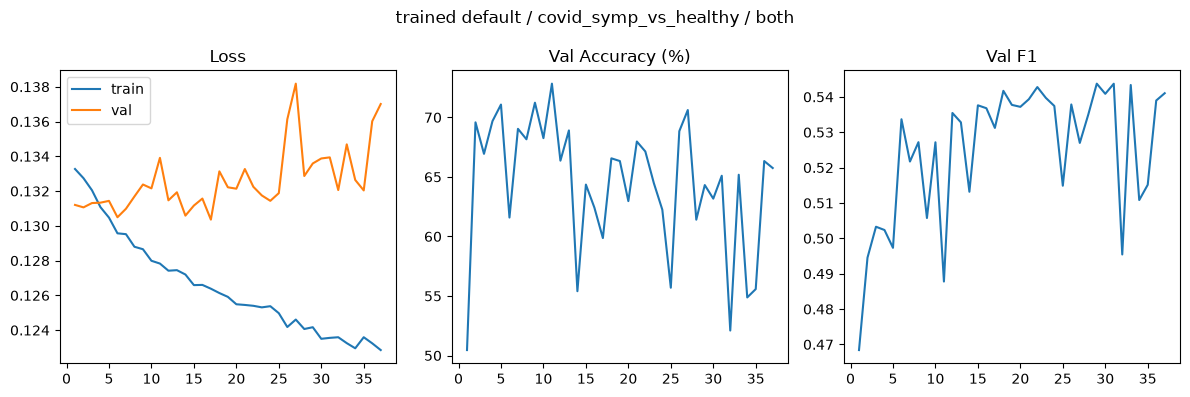

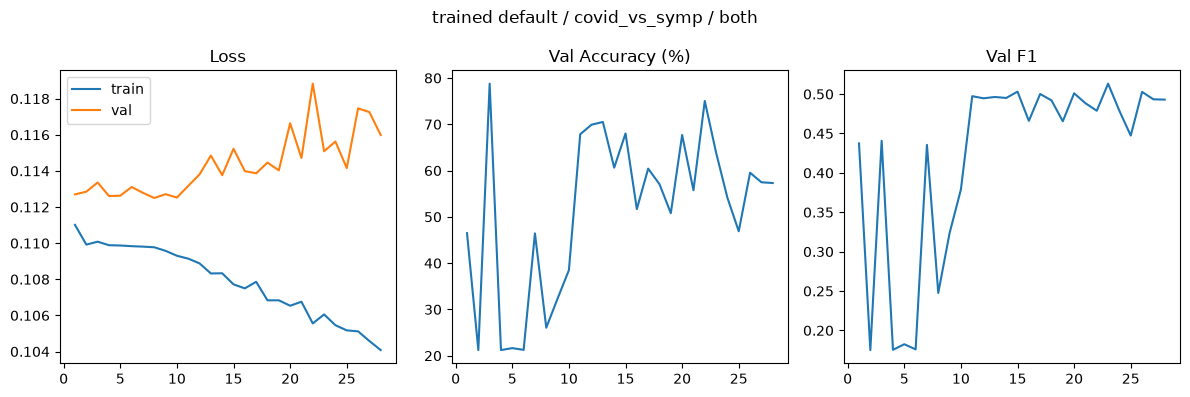

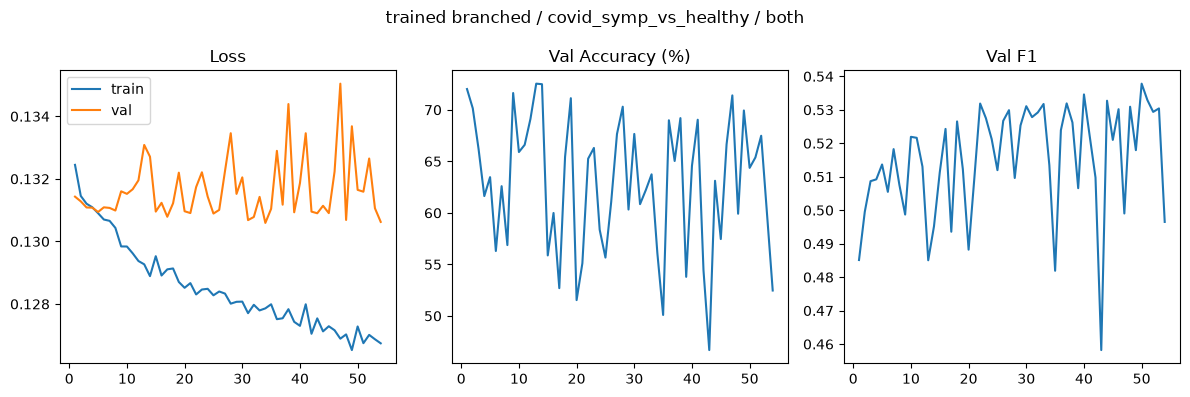

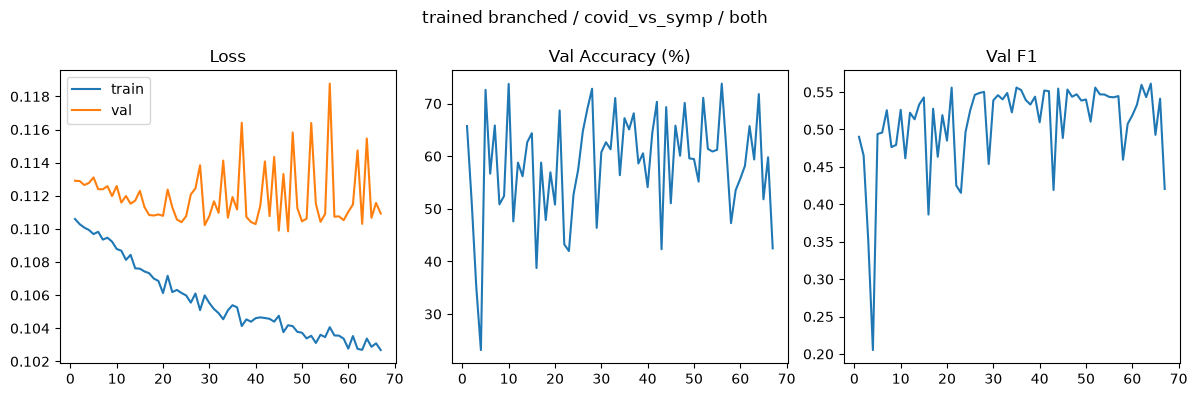

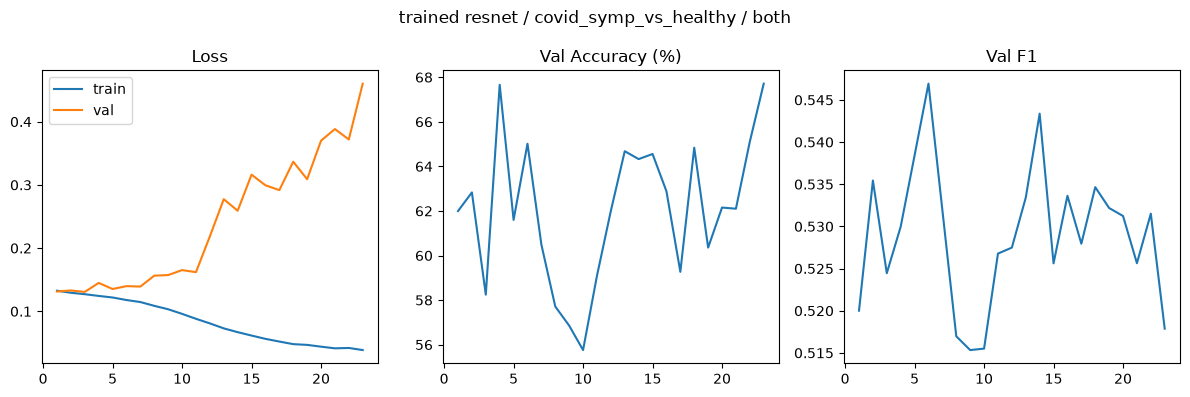

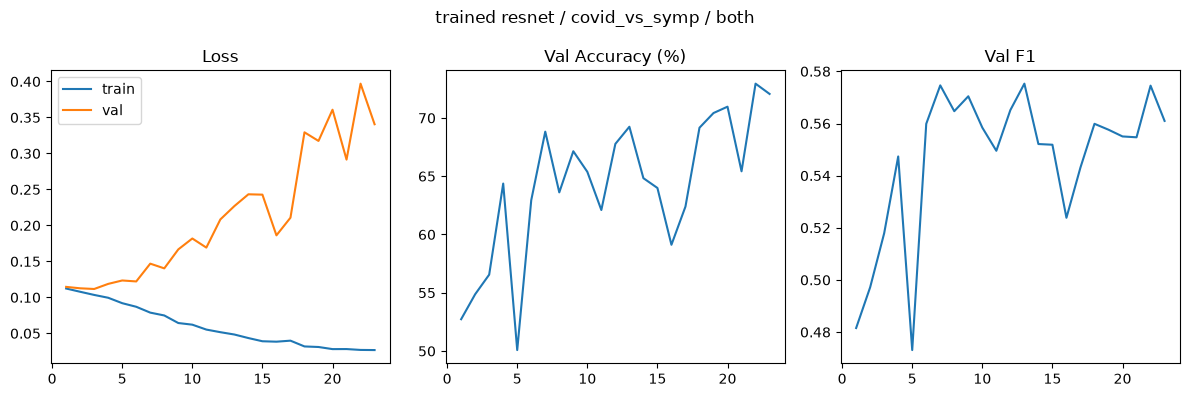

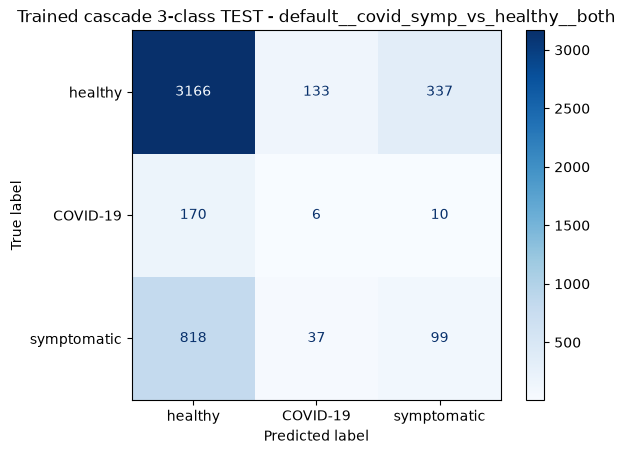

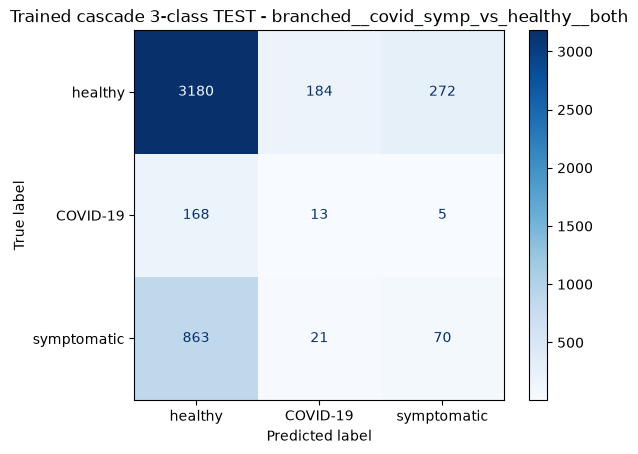

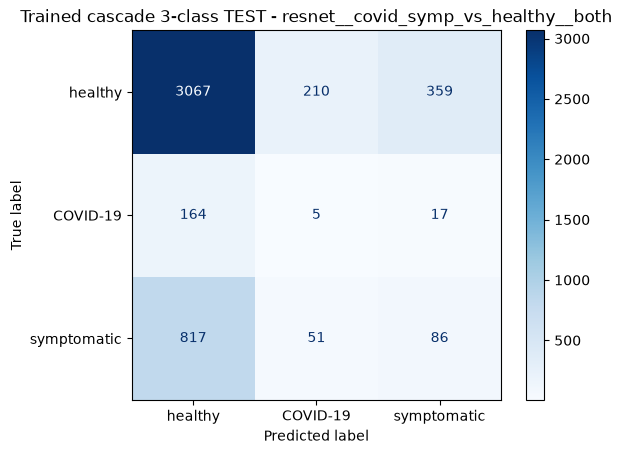

trained default stage1 TEST [both] tau=0.500
[[2808  828]
 [ 779  361]]


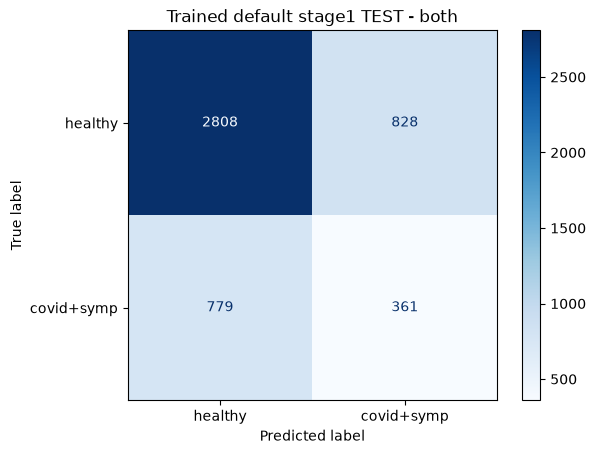

trained default stage2 TEST [both] tau=0.500
[[604 350]
 [ 87  99]]


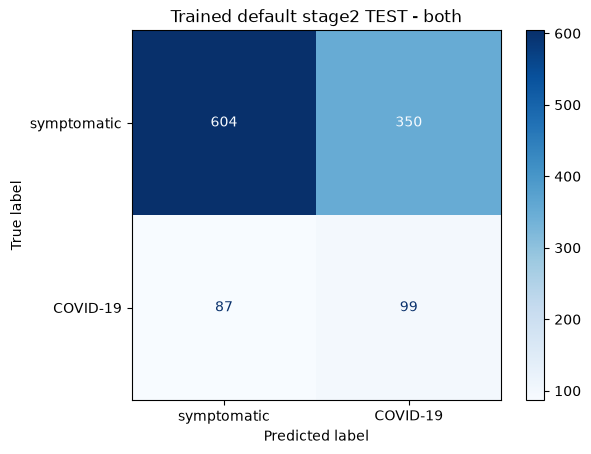

trained branched stage1 TEST [both] tau=0.500
[[1862 1774]
 [ 478  662]]


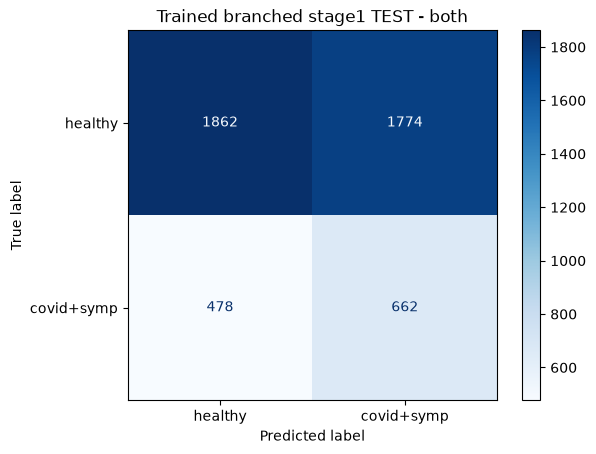

trained branched stage2 TEST [both] tau=0.500
[[343 611]
 [ 36 150]]


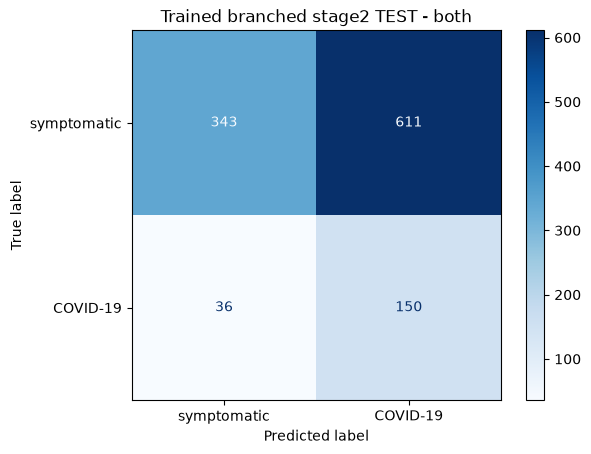

trained resnet stage1 TEST [both] tau=0.500
[[3091  545]
 [ 920  220]]


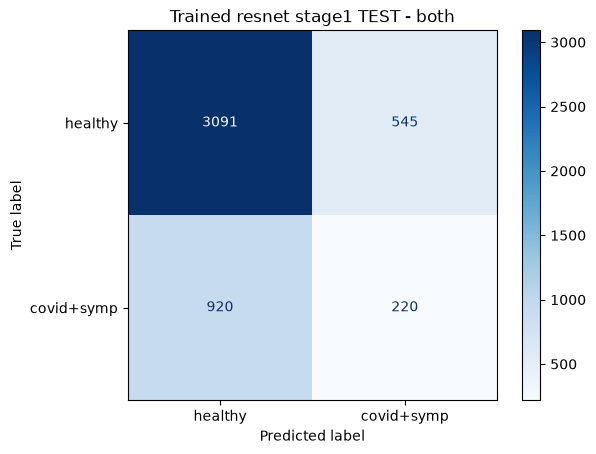

trained resnet stage2 TEST [both] tau=0.500
[[800 154]
 [141  45]]


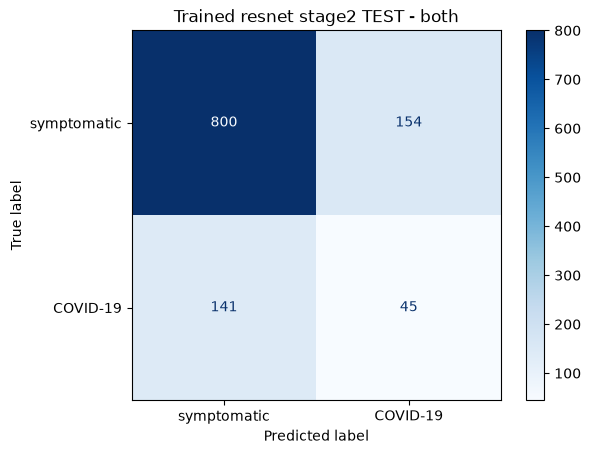

shape: (18, 8)
+-----------------------------------+------------+---------+---------+---------+---------+---------+--------+
| experiment                        | metric     | max     | min     | final   | avg     | std     | epochs |
| ---                               | ---        | ---     | ---     | ---     | ---     | ---     | ---    |
| str                               | str        | f64     | f64     | f64     | f64     | f64     | i64    |
+===========================================================================================================+
| trained_default__covid_symp_vs... | train_loss | 0.1333  | 0.1229  | 0.1229  | 0.1265  | 0.0028  | 37     |
| trained_default__covid_symp_vs... | val_loss   | 0.1382  | 0.1304  | 0.137   | 0.1326  | 0.0018  | 37     |
| trained_default__covid_symp_vs... | val_acc    | 72.8318 | 50.4598 | 65.7471 | 64.4011 | 5.4827  | 37     |
| trained_default__covid_vs_symp... | train_loss | 0.111   | 0.1041  | 0.1041  | 0.1078  | 0.0019  | 28  

In [22]:
# ---- Multi-model plots + summary table (mirrors cascade plot cell) ----
# History plots, 3-class CMs, stage CMs, summary table — all labeled trained_*.
# crash recovery: results from CSVs, preds from eval state
import matplotlib.pyplot as plt
if "trained_results" not in globals() or not trained_results:
    trained_results = {}
    for mn, cfg in TRAINED_RUNS:
        for task in ("covid_symp_vs_healthy", "covid_vs_symp"):
            key = f"{mn}__{task}__{cfg}"
            csv = f"trained_{key}_experiment_stats.csv"
            if os.path.exists(csv):
                df = pl.read_csv(csv)
                trained_results[key] = {col: df[col].to_list() for col in CSV_COLS}
    print("=> trained_results rebuilt from trained_*_experiment_stats.csv")

if "trained_preds" not in globals():
    _tep = "run_state/trained_eval_state.pt"
    assert os.path.exists(_tep), "run_state/trained_eval_state.pt missing — run the trained-eval cell first"
    _tev = torch.load(_tep, weights_only=False)
    trained_preds, test_y3_t = _tev["trained_preds"], _tev["test_y3"]
    trained_eval_rows, trained_stage2_rows = _tev["trained_eval_rows"], _tev["trained_stage2_rows"]
    print("=> trained preds/test_y3 restored from run_state/trained_eval_state.pt")

# history plots
for (mn, cfg) in TRAINED_RUNS:
    for task in ("covid_symp_vs_healthy", "covid_vs_symp"):
        key = f"{mn}__{task}__{cfg}"
        if key not in trained_results:
            continue
        hist = trained_results[key]
        fig, (ax_loss, ax_acc, ax_f1) = plt.subplots(1, 3, figsize=(12, 4))
        fig.suptitle(f"trained {mn} / {task} / {cfg}")
        epochs = range(1, len(hist["train_loss"]) + 1)
        ax_loss.plot(epochs, hist["train_loss"], label="train")
        ax_loss.plot(epochs, hist["val_loss"], label="val")
        ax_loss.set_title("Loss"); ax_loss.legend()
        ax_acc.plot(epochs, hist["val_acc"]); ax_acc.set_title("Val Accuracy (%)")
        ax_f1.plot(epochs, hist["val_F1"]); ax_f1.set_title("Val F1")
        fig.tight_layout()
        fig.savefig(f"figures/trained_{key}_history.png", bbox_inches="tight")
        plt.show(fig)
        plt.close(fig)

# 3-class cascade CMs
for key, pred3 in trained_preds.items():
    cm3 = confusion_matrix(test_y3_t, pred3, labels=[0, 1, 2])
    disp = ConfusionMatrixDisplay(cm3, display_labels=list(LABELS_INV.values()))
    disp.plot(cmap="Blues")
    plt.title(f"Trained cascade 3-class TEST - {key}")
    plt.savefig(f"figures/trained_cascade_3class_{key}.png", bbox_inches="tight")
    plt.show()
    plt.close("all")

# stage-1/stage-2 binary CMs (need model-aware inference + splits in memory)
if "_collect_probs_mn" not in globals() or "test_subset" not in globals() or "trained_models_all" not in globals():
    print("=> skipping trained stage CMs: _collect_probs_mn/test_subset/trained_models_all not in memory")
else:
    for mn, cfg in TRAINED_RUNS:
        if cfg not in trained_models_all.get(mn, {}):
            continue
        for stage, task, idxs_val, idxs_test, labels_disp, positive in [
            ("stage1", "covid_symp_vs_healthy", val_subset.indices, test_subset.indices, ["healthy", "covid+symp"], -1),
            ("stage2", "covid_vs_symp", sick_val_idx, sick_test_idx, ["symptomatic", "COVID-19"], 1),
        ]:
            m = trained_models_all[mn][cfg].get(stage)
            if m is None:
                continue
            tp, ty = _collect_probs_mn(m, mn, idxs_test, positive=positive, task=task)
            _, vy = _collect_probs_mn(m, mn, idxs_val, positive=positive, task=task)
            tau = tune_threshold(vy, tp)
            p = (tp >= tau).astype(int)
            cm = confusion_matrix(ty, p, labels=[0, 1])
            print(f"trained {mn} {stage} TEST [{cfg}] tau={tau:.3f}")
            print(cm)
            disp = ConfusionMatrixDisplay(cm, display_labels=labels_disp)
            disp.plot(cmap="Blues")
            plt.title(f"Trained {mn} {stage} TEST - {cfg}")
            plt.savefig(f"figures/trained_{mn}_{stage}_{task}_{cfg}_cm.png", bbox_inches="tight")
            plt.show()
            plt.close("all")

# summary table: same stats as results_table, per trained run, + epoch counts
rows = []
for key, hist in trained_results.items():
    for metric in ("train_loss", "val_loss", "val_acc"):
        vals = hist[metric]
        rows.append({
            "experiment": f"trained_{key}", "metric": metric,
            "max": round(max(vals), 4), "min": round(min(vals), 4),
            "final": round(vals[-1], 4), "avg": round(sum(vals) / len(vals), 4),
            "std": round(float(np.std(vals)), 4), "epochs": len(vals),
        })
summary_df = pl.DataFrame(rows)
pl.Config.set_ascii_tables()  # ponytail: cp1252 console can't render polars box chars
with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=120):
    print(summary_df)
summary_df.write_csv("trained_experiment_summary.csv")
# eval CSVs rewritten here too so a fresh-kernel restore refreshes them
pl.DataFrame(trained_eval_rows).write_csv("trained_cascade_eval_results.csv")
pl.DataFrame(trained_stage2_rows).write_csv("trained_stage2_standalone_eval.csv")
print("All trained-model figures + CSVs written to figures/ and notebook root.")